# Evaluación Parcial N° 2 — Redes Neuronales Convolucionales (CNN)
## Programa base CNN-SIMPSON: clasificación de personajes de *Los Simpson*

**Asignatura:** DLY0100 Deep Learning · **Ponderación:** 30 % · **Modalidad:** encargo en parejas + presentación individual (10 min)

### Contexto del problema

Se cuenta con un conjunto de **imágenes de personajes de *Los Simpson*** extraídas de distintos capítulos de la serie. Cada imagen muestra a **un personaje** en escenas, poses, tamaños y fondos muy variados.

**Objetivo:** construir una **red neuronal convolucional (CNN)** que, a partir de una imagen, **identifique a cuál de los 18 personajes** corresponde.

| | |
|---|---|
| **Tipo de problema** | Clasificación **multiclase** (18 clases) |
| **Entrada** | Imagen a color (RGB) de tamaño variable |
| **Salida** | Nombre del personaje |
| **Archivos** | `simpsons_train.tar` (entrenamiento) y `simpsons_test.tar` (prueba), entregados por el docente |
| **Fuente original** | *The Simpsons Characters Data* (A. Attia, Kaggle) |

## ¿Qué deben demostrar?

1. Cargar y **preprocesar** correctamente las imágenes.
2. **Diseñar e implementar** una CNN en Python con **TensorFlow/Keras** (o PyTorch), con el código **documentado**.
3. **Justificar** la arquitectura propuesta: configuración de capas (convolución, *pooling*, *padding*, *stride*, capas densas…) e hiperparámetros.
4. **Comparar distintas arquitecturas y herramientas** (por ejemplo: CNN simple vs. CNN más profunda vs. ResNet / *transfer learning*), explicando las diferencias de rendimiento.
5. **Ajustar hiperparámetros** (tasa de aprendizaje, optimizador, *batch size*, épocas, *dropout*, regularización, *data augmentation*…) y mostrar su **impacto** con métricas y gráficos.
6. **Evaluar** el modelo con **Accuracy, Loss, Precision, Recall y F1-Score** (por clase y promedio) y **matriz de confusión**.
7. **Justificar la elección del modelo final** con evidencia experimental.

> Este notebook **solo carga y describe los datos**. Todo el preprocesamiento, los modelos y el análisis son parte de su trabajo.

## 0. Librerías y configuración

In [1]:
import os
import glob
import tarfile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
np.random.seed(SEED)

IMG_SIZE = 64   # todas las imágenes se redimensionan a IMG_SIZE x IMG_SIZE (pueden cambiarlo y justificarlo)

## 1. Obtener los archivos

Necesitan los dos archivos entregados por el docente: **`simpsons_train.tar`** y **`simpsons_test.tar`**. Usen **una** de estas opciones:

- **Opción A — Subirlos a Colab / dejarlos junto al notebook:** en Colab, ícono de carpeta (panel izquierdo) → *Subir*. En Jupyter local, déjenlos en la misma carpeta que este notebook. Si no están, en Colab la celda les abrirá un selector para subirlos.
- **Opción B — Enlace de Google Drive:** peguen el enlace de cada archivo en `ENLACE_TRAIN` y `ENLACE_TEST`. El archivo debe estar compartido como *"Cualquier persona con el enlace"*.

> 💡 Los archivos pesan varios cientos de MB: la **Opción B** es más rápida en Colab que subirlos desde su computador.

In [2]:
ARCHIVO_TRAIN = "simpsons_train.tar"
ARCHIVO_TEST  = "simpsons_test.tar"

ENLACE_TRAIN = ""   # opcional: enlace de Google Drive a simpsons_train.tar
ENLACE_TEST  = ""   # opcional: enlace de Google Drive a simpsons_test.tar


def buscar_archivo(nombre):
    # Acepta variantes del nombre: .tar, .tar.gz, .tgz y "simpsons_test_tar"
    base = nombre.replace(".tar", "")
    for candidato in [nombre, base + ".tar.gz", base + ".tgz", base + "_tar"]:
        if os.path.exists(candidato):
            return candidato
    return None


def obtener_archivo(nombre, enlace=""):
    ruta = buscar_archivo(nombre)
    if ruta:
        return ruta
    if enlace:                                   # Opción B: descarga desde Google Drive
        import gdown                             # viene instalado en Colab (local: pip install gdown)
        gdown.download(enlace, nombre, quiet=False, fuzzy=True)
        return nombre
    try:                                         # Opción A en Colab: abrir selector para subir
        from google.colab import files
        print(f"Selecciona el archivo {nombre}")
        subido = files.upload()
        return list(subido.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"No se encontró {nombre}. Déjalo junto al notebook o indica su enlace.")


ruta_train = obtener_archivo(ARCHIVO_TRAIN, ENLACE_TRAIN)
ruta_test  = obtener_archivo(ARCHIVO_TEST,  ENLACE_TEST)
print("Entrenamiento:", ruta_train)
print("Prueba       :", ruta_test)

Entrenamiento: simpsons_train.tar
Prueba       : simpsons_test.tar


### Descomprimir

In [3]:
DIR_TRAIN = "simpsons_train"
DIR_TEST  = "simpsons_test"

def descomprimir(ruta_tar, destino):
    if os.path.isdir(destino) and os.listdir(destino):
        print(f"'{destino}' ya existe, no se vuelve a descomprimir.")
        return
    os.makedirs(destino, exist_ok=True)
    with tarfile.open(ruta_tar, "r:*") as tar:    # "r:*" detecta si viene comprimido (gz) o no
        try:
            tar.extractall(destino, filter="data")   # extracción segura (Python >= 3.12)
        except TypeError:
            tar.extractall(destino)
    print(f"'{ruta_tar}' descomprimido en '{destino}'.")

descomprimir(ruta_train, DIR_TRAIN)
descomprimir(ruta_test,  DIR_TEST)

'simpsons_train' ya existe, no se vuelve a descomprimir.
'simpsons_test' ya existe, no se vuelve a descomprimir.


## 2. Las 18 clases (personajes)

El modelo debe clasificar estos **18 personajes**. Usen este diccionario para pasar del **número de clase** (salida de la red) al **nombre del personaje**.

In [4]:
MAP_CHARACTERS = {
    0: "abraham_grampa_simpson",  1: "apu_nahasapeemapetilon",  2: "bart_simpson",
    3: "charles_montgomery_burns", 4: "chief_wiggum",           5: "comic_book_guy",
    6: "edna_krabappel",          7: "homer_simpson",           8: "kent_brockman",
    9: "krusty_the_clown",       10: "lisa_simpson",           11: "marge_simpson",
   12: "milhouse_van_houten",    13: "moe_szyslak",            14: "ned_flanders",
   15: "nelson_muntz",           16: "principal_skinner",      17: "sideshow_bob",
}
NUM_CLASSES = len(MAP_CHARACTERS)
CLASE_DE = {nombre: i for i, nombre in MAP_CHARACTERS.items()}   # nombre -> número de clase
print("Número de clases:", NUM_CLASSES)

Número de clases: 18


## 3. Cargar las imágenes

- **Entrenamiento:** una carpeta por personaje (`simpsons_train/<personaje>/pic_XXXX.jpg`).
- **Prueba:** el nombre del personaje viene en el nombre del archivo (`<personaje>_<n>.jpg`).

La función `cargar_imagenes` reconoce ambos formatos, convierte cada imagen a **RGB**, la redimensiona a `IMG_SIZE x IMG_SIZE` y devuelve:

- `X`: arreglo `(n_imágenes, IMG_SIZE, IMG_SIZE, 3)` con valores enteros **0–255** (`uint8`, **sin normalizar**).
- `y`: arreglo `(n_imágenes,)` con el **número de clase** (0–17).
- `tamanos`: tamaño original `(ancho, alto)` de cada imagen.

In [5]:
EXTENSIONES = (".jpg", ".jpeg", ".png", ".bmp")

def etiqueta_de(ruta):
    # 1) ¿la carpeta que contiene la imagen es un personaje?  (formato entrenamiento)
    carpeta = os.path.basename(os.path.dirname(ruta))
    if carpeta in CLASE_DE:
        return CLASE_DE[carpeta]
    # 2) ¿el nombre del archivo empieza con un personaje? (formato prueba: homer_simpson_12.jpg)
    archivo = os.path.splitext(os.path.basename(ruta))[0]
    nombre = "_".join(archivo.split("_")[:-1])
    return CLASE_DE.get(nombre)          # None si no es uno de los 18 personajes


def cargar_imagenes(directorio, img_size=IMG_SIZE):
    rutas = sorted(r for r in glob.glob(os.path.join(directorio, "**", "*"), recursive=True)
                   if r.lower().endswith(EXTENSIONES) and not os.path.basename(r).startswith("._"))
    X, y, tamanos, omitidas = [], [], [], 0
    for ruta in rutas:
        clase = etiqueta_de(ruta)
        if clase is None:
            omitidas += 1
            continue
        try:
            with Image.open(ruta) as img:
                tamanos.append(img.size)
                img = img.convert("RGB").resize((img_size, img_size))
                X.append(np.asarray(img, dtype=np.uint8))
                y.append(clase)
        except OSError:
            omitidas += 1                # archivo dañado
    print(f"{directorio}: {len(X)} imágenes cargadas ({omitidas} omitidas)")
    return np.stack(X), np.array(y), np.array(tamanos)


X_train, y_train, tamanos_train = cargar_imagenes(DIR_TRAIN)
X_test,  y_test,  tamanos_test  = cargar_imagenes(DIR_TEST)

print("\nX_train:", X_train.shape, X_train.dtype, " | y_train:", y_train.shape)
print("X_test :", X_test.shape,  X_test.dtype,  " | y_test :", y_test.shape)

simpsons_train: 18992 imágenes cargadas (0 omitidas)


simpsons_test: 890 imágenes cargadas (0 omitidas)

X_train: (18992, 64, 64, 3) uint8  | y_train: (18992,)
X_test : (890, 64, 64, 3) uint8  | y_test : (890,)


## 4. Primera mirada a los datos

### Imágenes de ejemplo

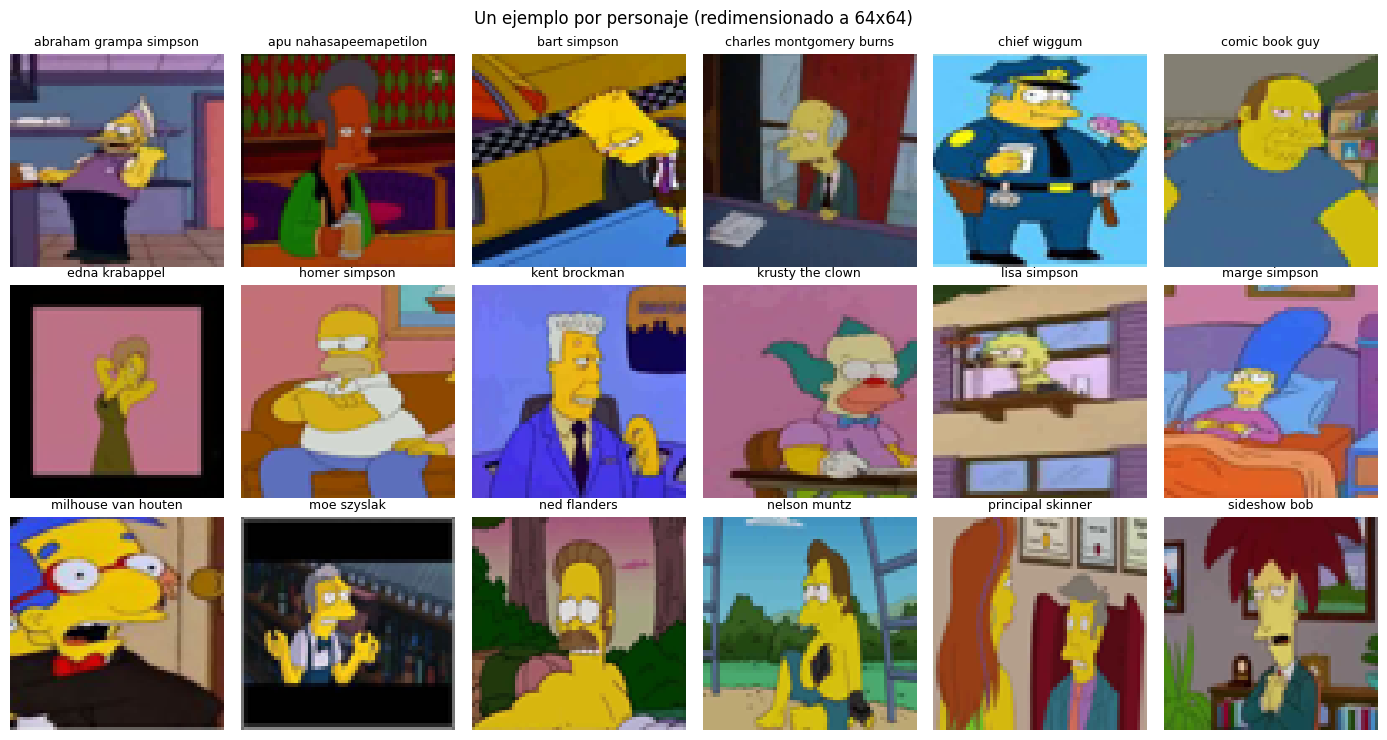

In [6]:
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for clase, ax in zip(range(NUM_CLASSES), axes.ravel()):
    idx = np.where(y_train == clase)[0]
    if len(idx):
        ax.imshow(X_train[np.random.choice(idx)])
    ax.set_title(MAP_CHARACTERS[clase].replace("_", " "), fontsize=9)
    ax.axis("off")
plt.suptitle(f"Un ejemplo por personaje (redimensionado a {IMG_SIZE}x{IMG_SIZE})")
plt.tight_layout()
plt.show()

### Distribución de clases

,train,test,train (%)
personaje,,,
homer_simpson,2246,50,11.8
ned_flanders,1454,49,7.7
moe_szyslak,1452,50,7.6
lisa_simpson,1354,50,7.1
bart_simpson,1342,50,7.1
marge_simpson,1291,50,6.8
krusty_the_clown,1206,50,6.4
principal_skinner,1194,50,6.3
charles_montgomery_burns,1193,48,6.3


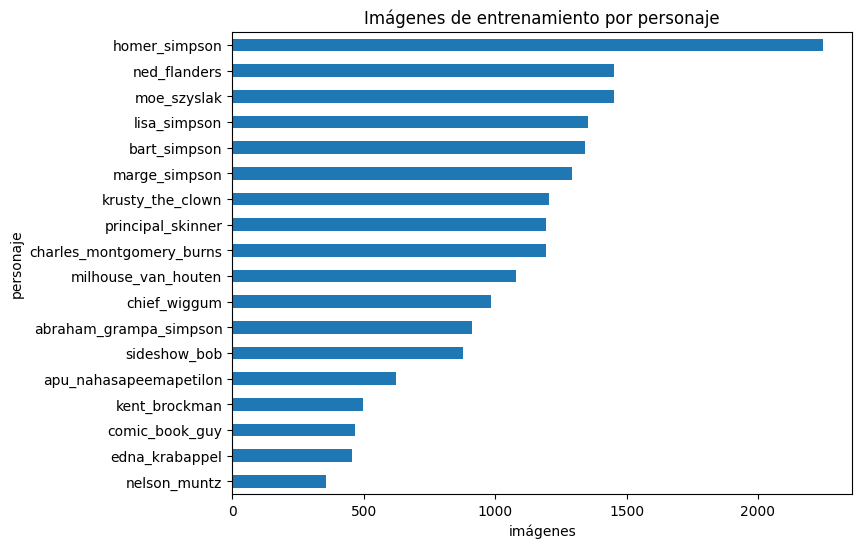

Clase más frecuente: 2246 imágenes | menos frecuente: 358 imágenes | razón: 6.3x


In [7]:
conteo = pd.DataFrame({
    "personaje": [MAP_CHARACTERS[i] for i in range(NUM_CLASSES)],
    "train": [int((y_train == i).sum()) for i in range(NUM_CLASSES)],
    "test":  [int((y_test  == i).sum()) for i in range(NUM_CLASSES)],
}).set_index("personaje")
conteo["train (%)"] = (conteo["train"] / conteo["train"].sum() * 100).round(1)
conteo = conteo.sort_values("train", ascending=False)
display(conteo)

conteo["train"].plot(kind="barh", figsize=(8, 6), color="tab:blue",
                     title="Imágenes de entrenamiento por personaje")
plt.xlabel("imágenes")
plt.gca().invert_yaxis()
plt.show()

mayor, menor = conteo["train"].max(), conteo["train"].min()
print(f"Clase más frecuente: {mayor} imágenes | menos frecuente: {menor} imágenes"
      + (f" | razón: {mayor / menor:.1f}x" if menor > 0 else ""))

### Tamaño original de las imágenes

,ancho,alto
count,18992.0,18992.0
mean,408.0,417.0
std,150.0,63.0
min,256.0,256.0
25%,288.0,379.0
50%,320.0,432.0
75%,576.0,480.0
max,1912.0,1072.0


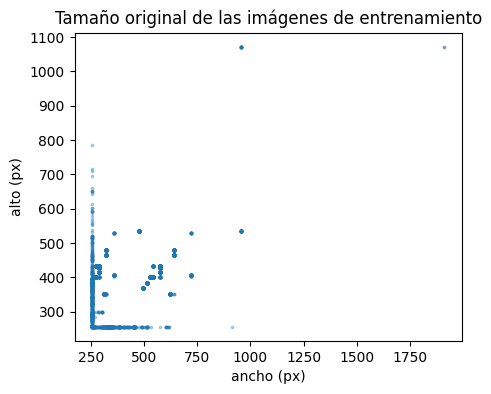

In [8]:
tam = pd.DataFrame(tamanos_train, columns=["ancho", "alto"])
display(tam.describe().round(0))

plt.figure(figsize=(5, 4))
plt.scatter(tam["ancho"], tam["alto"], s=3, alpha=0.3)
plt.xlabel("ancho (px)"); plt.ylabel("alto (px)")
plt.title("Tamaño original de las imágenes de entrenamiento")
plt.show()

## 5. Consideraciones importantes

1. **Clases desbalanceadas.** Algunos personajes tienen muchas más imágenes que otros. Un buen *Accuracy* global puede esconder que el modelo falla con los personajes con pocas imágenes: revisen **Precision, Recall y F1 por clase** (`classification_report`) y la **matriz de confusión**. Expliquen si usan *macro* o *weighted* F1 y por qué.
2. **Imágenes de tamaño variable.** Se redimensionan a `IMG_SIZE x IMG_SIZE`. Un tamaño mayor conserva más detalle pero cuesta más memoria y tiempo de entrenamiento. Si lo cambian, **justifíquenlo**.
3. **Normalización.** `X_train` y `X_test` vienen en **0–255** (`uint8`). Deben escalarlos (por ejemplo a 0–1) antes de entrenar.
4. **Etiquetas.** `y` contiene números 0–17. Según la función de pérdida que elijan, deben usarse tal cual (`sparse_categorical_crossentropy`) o en *one-hot* (`categorical_crossentropy`).
5. **Validación.** El conjunto de **prueba** (`X_test`) se usa **solo para la evaluación final**. Para ajustar hiperparámetros y comparar modelos, separen un conjunto de **validación** desde `X_train` (idealmente **estratificado**).
6. **Sobreajuste.** Con imágenes, las CNN sobreajustan rápido. Vigilen las curvas de *loss/accuracy* de entrenamiento vs. validación y consideren *Dropout*, *BatchNormalization*, regularización L2, *EarlyStopping* y *data augmentation*.
7. **Recursos.** En Colab activen la **GPU** (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*). Guarden los mejores modelos con `ModelCheckpoint` para no perder entrenamientos si se desconecta la sesión.
8. **Reproducibilidad.** Fijen semillas (`SEED`) para que sus comparaciones sean justas.

## 6. Entregables y pauta de evaluación

**Producto 1 — Este cuaderno (informe), desarrollado en Google Colab** con explicaciones en Markdown, código comentado y modularizado, gráficos y tablas, y una sección de **conclusiones**.

**Producto 2 — Presentación oral individual** (máx. 10 min) usando el cuaderno como soporte: problema y objetivos → arquitectura CNN → decisiones clave → resultados y métricas → comparación de configuraciones y mejoras → conclusiones.

| Dimensión | Indicador | Peso |
|---|---|---|
| **Encargo (parejas) — 20 %** | IE 2.1.1 Analiza y justifica el proceso de construcción del modelo CNN y la selección de herramientas | 4 % |
| | IE 2.1.2 Evalúa comparativamente diferentes arquitecturas y herramientas, explicando las diferencias de rendimiento | 4 % |
| | IE 2.1.3 Evalúa el rendimiento con métricas (accuracy, loss, precision, recall, F1…) e interpreta los resultados | 2 % |
| | IE 2.2.1 Propone la arquitectura CNN, justificando capas e hiperparámetros | 4 % |
| | IE 2.2.2 Evalúa críticamente los ajustes de hiperparámetros y su impacto en el rendimiento | 4 % |
| | IE 2.2.3 Evalúa y justifica la selección del modelo final con métricas y pruebas | 2 % |
| **Presentación (individual) — 80 %** | IEP 2.1.1 Explica el desarrollo del modelo, fortalezas y debilidades de las herramientas | 16 % |
| | IEP 2.1.2 Presenta la comparación de arquitecturas y herramientas de forma clara y argumentada | 16 % |
| | IEP 2.1.3 Explica los resultados y su impacto en la solución del caso | 16 % |
| | IEP 2.2.1 Explica la arquitectura propuesta y su alineación con el problema | 8 % |
| | IEP 2.2.2 Demuestra las mejoras por ajuste de hiperparámetros con gráficos comparativos | 8 % |
| | IEP 2.2.3 Explica la elección del modelo final y su impacto en la solución | 16 % |

> El desarrollo del encargo es en parejas, pero **la presentación y la defensa son individuales**: ambos integrantes deben poder explicar y justificar cualquier parte del cuaderno.

## 7. Su trabajo comienza aquí ⬇️

**Integrante:** Diego Antonio Cortes Baeza *(trabajo individual)*

> **Nota de ejecución:** este cuaderno se ejecutó completo, de principio a fin, en **CPU (12 núcleos, sin GPU)**; el tiempo total fue de ≈ 134 minutos y los tiempos por época que se reportan corresponden a ese equipo. En Google Colab con GPU el entrenamiento es bastante más rápido y las métricas pueden variar levemente (décimas de punto) por el no-determinismo de las operaciones en GPU. Los modelos entrenados quedan en `resultados/`: si esa carpeta se sube junto al cuaderno, `REUTILIZAR_RESULTADOS = True` los carga sin volver a entrenar.

Estructura sugerida (mantengan este orden en el cuaderno):

1. **Introducción:** descripción del problema y objetivo del modelo.
2. **Preprocesamiento:** normalización, separación entrenamiento / validación, codificación de etiquetas, *data augmentation* (si aplica).
3. **Modelo base (CNN):** definición de la arquitectura, `model.summary()` y justificación de cada bloque.
4. **Entrenamiento y ajuste de hiperparámetros:** configuraciones probadas y justificación (tabla resumen + curvas de entrenamiento).
5. **Comparación de arquitecturas/herramientas:** al menos **dos arquitecturas distintas** (ej.: CNN simple, CNN más profunda, ResNet, *transfer learning*), comparadas con las mismas métricas.
6. **Evaluación del modelo final sobre `X_test`:** Accuracy, Loss, Precision, Recall, F1-Score (por clase y promedio), matriz de confusión y ejemplos de aciertos y errores.
7. **Conclusiones:** desempeño del modelo, limitaciones y posibles mejoras.

### 1. Introducción

#### 1.1 Descripción del problema

Se busca **reconocer automáticamente a 18 personajes de *Los Simpson*** a partir de fotogramas de la serie. Es un problema de **clasificación multiclase de imágenes** con varias dificultades reales:

- **Alta variabilidad intra-clase:** el mismo personaje aparece de frente, de perfil, de espalda, a distintas escalas, con otros personajes en el cuadro y con fondos muy diferentes.
- **Baja variabilidad inter-clase en algunos pares:** varios personajes comparten piel amarilla, siluetas y paleta de colores parecidas (p. ej. Bart / Lisa / Nelson, o los adultos con camisa blanca: Homer, Skinner, Kent Brockman).
- **Clases desbalanceadas** en entrenamiento (de ~360 a ~2.250 imágenes por personaje), mientras que el conjunto de prueba está **balanceado** (~50 por personaje).
- **Tamaños originales variables** (≈ 256–950 px), que hay que llevar a una resolución fija.

#### 1.2 Objetivo del modelo

Construir, comparar y optimizar **redes neuronales convolucionales (CNN)** con **TensorFlow/Keras** que, dada una imagen, predigan el personaje con el **mejor equilibrio entre todas las clases**.

#### 1.3 ¿Por qué una CNN y no un MLP?

Un MLP trata cada píxel como una variable independiente: con una imagen de 64×64×3 tendría 12.288 entradas totalmente conectadas, perdería la **estructura espacial** y no sería invariante a traslaciones. Una CNN, en cambio:

1. **Comparte pesos** (el mismo filtro recorre toda la imagen) → muchos menos parámetros.
2. Aprende **jerarquías de características**: bordes → texturas/colores → partes (pelo de Marge, barba de Abe, lentes de Skinner) → personaje completo.
3. Es **aproximadamente invariante a la traslación** gracias a la convolución y al *pooling*.

#### 1.4 Métrica principal

Como el conjunto de prueba está balanceado y **todos los personajes importan por igual**, la métrica principal para comparar y elegir modelos es el **F1-score macro** (promedio simple del F1 de cada clase), complementado con *accuracy*, *loss*, *precision* y *recall*. El F1 *weighted* se reporta como referencia, pero favorece a las clases con más ejemplos (Homer) y podría ocultar fallos en personajes poco frecuentes (Nelson, Edna).

#### 1.5 Metodología

```
Datos (.tar) → carga y redimensionado → split estratificado train/val → normalización + aumentación
   → CNN base → ajuste de hiperparámetros (un factor a la vez, sobre validación)
   → comparación de arquitecturas (CNN simple · CNN profunda · MobileNetV2 transfer learning)
   → comparación de herramientas (Keras vs PyTorch, misma arquitectura)
   → selección del modelo final por F1-macro en validación → evaluación única sobre test
```

#### 1.6 Herramientas seleccionadas y justificación

| Herramienta | Uso en el trabajo | Ventajas | Limitaciones |
|---|---|---|---|
| **TensorFlow 2 + Keras 3** | Definición, entrenamiento y guardado de las CNN | API de alto nivel (`Sequential`/funcional), *callbacks* listos (`EarlyStopping`, `ModelCheckpoint`, `ReduceLROnPlateau`), capas de preprocesamiento y aumentación **dentro del modelo**, modelos pre-entrenados en `keras.applications`, soporte GPU transparente en Colab | Menos control fino del ciclo de entrenamiento; errores en modo grafo a veces poco legibles; sin soporte GPU nativo en Windows (TF > 2.10) |
| **`tf.data`** | *Pipeline* de entrada (barajado, lotes, *prefetch*) | Carga en paralelo con el entrenamiento, eficiente en memoria | Curva de aprendizaje mayor que pasar arreglos NumPy |
| **PyTorch** | Re-implementación de la CNN base para **comparar herramientas** | Control explícito y "pythónico" del ciclo de entrenamiento, depuración sencilla, muy usado en investigación | Más código: bucle, *early stopping* y *checkpoints* se programan a mano |
| **scikit-learn** | Split estratificado, pesos de clase, métricas (`classification_report`, matriz de confusión) | Métricas estándar y confiables, independientes del *framework* | No entrena redes profundas |
| **NumPy · Pandas · Matplotlib · Seaborn** | Manipulación de datos, tablas y gráficos | Ecosistema estándar, integración con Jupyter/Colab | — |

#### 1.7 Entorno de ejecución y utilidades comunes

La siguiente celda importa las librerías de *Deep Learning*, verifica si hay GPU, fija las semillas (**reproducibilidad**: todas las comparaciones parten de la misma inicialización) y define dos utilidades:

- `REUTILIZAR_RESULTADOS`: cada modelo entrenado se guarda en `resultados/`. Si Colab se desconecta, al re-ejecutar el cuaderno se cargan los modelos ya entrenados en lugar de volver a entrenarlos.
- `guardar_figura`: guarda cada gráfico en `figuras/` para usarlo en la presentación.

In [9]:
import os, time, json, copy
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"          # oculta mensajes informativos de TensorFlow
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import platform
import tensorflow as tf
import keras
from keras import layers, callbacks, optimizers, regularizers
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, log_loss,
                             classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

tf.get_logger().setLevel("ERROR")                  # oculta advertencias repetitivas de retracing
gpus = tf.config.list_physical_devices("GPU")
print(f"Python {platform.python_version()} | TensorFlow {tf.__version__} | Keras {keras.__version__}")
print("Dispositivo:", f"GPU ({len(gpus)})" if gpus else f"CPU ({os.cpu_count()} núcleos lógicos)")


def fijar_semillas(seed=SEED):
    # Fija las semillas de Python, NumPy y TensorFlow a la vez
    keras.utils.set_random_seed(seed)

fijar_semillas()

DIR_RESULTADOS, DIR_FIGURAS = "resultados", "figuras"
os.makedirs(DIR_RESULTADOS, exist_ok=True)
os.makedirs(DIR_FIGURAS, exist_ok=True)
REUTILIZAR_RESULTADOS = True     # True: si un modelo ya fue entrenado y guardado, se carga desde disco


def guardar_figura(nombre):
    # Guarda la figura actual en figuras/<nombre>.png (para la presentación)
    plt.savefig(os.path.join(DIR_FIGURAS, f"{nombre}.png"), dpi=150, bbox_inches="tight")


# Nombres cortos para gráficos y matrices de confusión
NOMBRE_CORTO = {0: "Abe", 1: "Apu", 2: "Bart", 3: "Burns", 4: "Wiggum", 5: "Comic Book Guy",
                6: "Edna", 7: "Homer", 8: "Kent", 9: "Krusty", 10: "Lisa", 11: "Marge",
                12: "Milhouse", 13: "Moe", 14: "Ned", 15: "Nelson", 16: "Skinner", 17: "Sideshow Bob"}

Python 3.11.0 | TensorFlow 2.21.0 | Keras 3.15.1
Dispositivo: CPU (12 núcleos lógicos)


### 2. Preprocesamiento

Decisiones de preprocesamiento y su justificación:

| Paso | Decisión | Justificación |
|---|---|---|
| Tamaño de entrada | **64×64** para las CNN entrenadas desde cero; **96×96** para *transfer learning* | 64×64 conserva rasgos distintivos (pelo, ropa, colores) con un costo de cómputo bajo, lo que permite **muchos experimentos**. MobileNetV2 fue pre-entrenada con resoluciones ≥ 96, por eso se le entrega 96×96 |
| Validación | *Split* **estratificado 85 % / 15 %** desde `X_train` | Mantiene la proporción de cada personaje en ambos conjuntos. El *test* queda **intacto** hasta la evaluación final (evita "espiar" el test al ajustar hiperparámetros) |
| Normalización | Capa `Rescaling(1/255)` **dentro del modelo** (0–255 → 0–1) | La normalización viaja con el modelo guardado: en producción se le entregan píxeles crudos y no hay riesgo de olvidarla. Valores pequeños estabilizan el descenso por gradiente |
| Etiquetas | Enteros 0–17 + `sparse_categorical_crossentropy` | Equivalente a *one-hot* + `categorical_crossentropy`, pero sin crear una matriz de 18 columnas |
| Desbalance | Pesos de clase `balanced` (se evalúan como experimento) | Penalizan más los errores en personajes con pocas imágenes |
| *Data augmentation* | Volteo horizontal, rotación, zoom, traslación y contraste aleatorios (capas Keras) | Simula la variabilidad real de los fotogramas (personaje desplazado, más cerca/lejos, otra iluminación) y reduce el sobreajuste. Se aplica **solo en entrenamiento** |

#### 2.1 Separación entrenamiento / validación (estratificada)

In [10]:
# Se separan índices (no imágenes) para poder reutilizar exactamente el mismo split con otra resolución
indices = np.arange(len(y_train))
idx_tr, idx_val = train_test_split(indices, test_size=0.15, stratify=y_train, random_state=SEED)

X_tr,  y_tr  = X_train[idx_tr],  y_train[idx_tr]
X_val, y_val = X_train[idx_val], y_train[idx_val]

# Diccionario con los conjuntos por resolución (se agregará 96x96 en la sección 5)
DATOS = {IMG_SIZE: {"train": (X_tr, y_tr), "val": (X_val, y_val), "test": (X_test, y_test)}}

print(f"Entrenamiento: {X_tr.shape}  | Validación: {X_val.shape}  | Prueba: {X_test.shape}")

# Verificación de la estratificación: el % de cada personaje es el mismo en train y val
reparto = pd.DataFrame({
    "train (%)": np.bincount(y_tr,  minlength=NUM_CLASSES) / len(y_tr)  * 100,
    "val (%)":   np.bincount(y_val, minlength=NUM_CLASSES) / len(y_val) * 100,
    "test (%)":  np.bincount(y_test, minlength=NUM_CLASSES) / len(y_test) * 100,
}, index=[NOMBRE_CORTO[i] for i in range(NUM_CLASSES)]).round(2)
display(reparto.T)

Entrenamiento: (16143, 64, 64, 3)  | Validación: (2849, 64, 64, 3)  | Prueba: (890, 64, 64, 3)


,Abe,Apu,Bart,Burns,Wiggum,Comic Book Guy,Edna,Homer,Kent,Krusty,Lisa,Marge,Milhouse,Moe,Ned,Nelson,Skinner,Sideshow Bob
train (%),4.81,3.28,7.07,6.28,5.19,2.47,2.41,11.83,2.62,6.35,7.13,6.80,5.68,7.64,7.66,1.88,6.29,4.62
val (%),4.81,3.26,7.06,6.28,5.19,2.46,2.39,11.83,2.63,6.35,7.13,6.81,5.69,7.65,7.65,1.90,6.28,4.63
test (%),5.39,5.62,5.62,5.39,5.62,5.51,5.62,5.62,5.62,5.62,5.62,5.62,5.51,5.62,5.51,5.62,5.62,5.28


#### 2.2 Normalización y pesos de clase

Se verifica el rango de los píxeles antes y después de la capa `Rescaling` y se calculan los **pesos de clase** con la fórmula `n_muestras / (n_clases · n_muestras_clase)`: una clase con la mitad de imágenes que el promedio recibe peso ≈ 2.

In [11]:
normalizar = layers.Rescaling(1.0 / 255)
muestra = normalizar(X_tr[:8].astype("float32")).numpy()
print(f"Antes : dtype={X_tr.dtype}, rango=[{X_tr.min()}, {X_tr.max()}]")
print(f"Después: dtype={muestra.dtype}, rango=[{muestra.min():.2f}, {muestra.max():.2f}]")

pesos = compute_class_weight(class_weight="balanced", classes=np.arange(NUM_CLASSES), y=y_tr)
CLASS_WEIGHT = {i: float(p) for i, p in enumerate(pesos)}
tabla_pesos = pd.DataFrame({"imágenes train": np.bincount(y_tr, minlength=NUM_CLASSES), "peso de clase": pesos.round(3)},
                           index=[NOMBRE_CORTO[i] for i in range(NUM_CLASSES)]).sort_values("peso de clase")
display(tabla_pesos.T)

Antes : dtype=uint8, rango=[0, 255]


Después: dtype=float32, rango=[0.00, 1.00]


,Homer,Ned,Moe,Lisa,Bart,Marge,Krusty,Burns,Skinner,Milhouse,Wiggum,Abe,Sideshow Bob,Apu,Kent,Comic Book Guy,Edna,Nelson
imágenes train,1909.00,1236.000,1234.000,1151.000,1141.000,1097.000,1025.000,1014.000,1015.000,917.000,838.00,776.000,745.000,530.000,423.00,399.000,389.000,304.00
peso de clase,0.47,0.726,0.727,0.779,0.786,0.818,0.875,0.884,0.884,0.978,1.07,1.156,1.204,1.692,2.12,2.248,2.305,2.95


#### 2.3 *Data augmentation*

Se define como un bloque de capas Keras que se inserta **al inicio del modelo**. Estas capas solo actúan durante `fit()`; en `predict()`/`evaluate()` dejan pasar la imagen sin cambios. Parámetros elegidos (moderados, para no deformar al personaje):

- `RandomFlip("horizontal")`: un personaje mirando a la izquierda sigue siendo el mismo personaje (no se usa volteo vertical: no es realista).
- `RandomRotation(0.05)`: ±18°, cámaras levemente inclinadas.
- `RandomZoom(0.15)` y `RandomTranslation(0.1, 0.1)`: personaje más cerca/lejos y descentrado.
- `RandomContrast(0.15)`: variaciones de iluminación entre escenas.

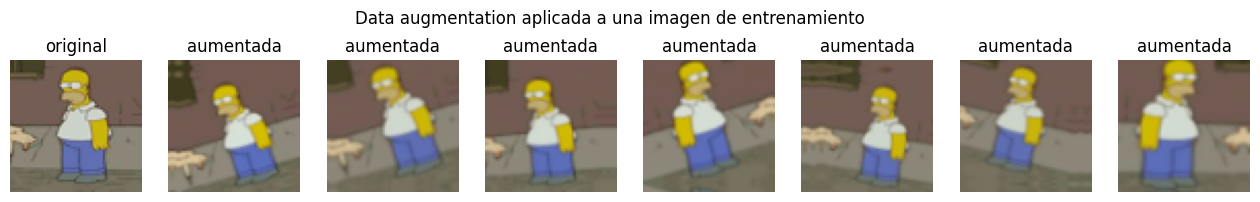

In [12]:
def crear_aumentacion():
    # Bloque de data augmentation (solo activo en entrenamiento)
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.15),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.15),
    ], name="data_augmentation")


# Visualización: una imagen original y 7 versiones aumentadas
aumentar = crear_aumentacion()
img = X_tr[np.where(y_tr == CLASE_DE["homer_simpson"])[0][0]]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(img); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(np.clip(aumentar(img[None].astype("float32"), training=True)[0].numpy(), 0, 255).astype("uint8"))
    ax.set_title("aumentada")
for ax in axes:
    ax.axis("off")
plt.suptitle("Data augmentation aplicada a una imagen de entrenamiento")
guardar_figura("02_data_augmentation")
plt.show()

#### 2.4 *Pipeline* de datos con `tf.data`

`crear_dataset` arma lotes a partir de los arreglos NumPy: baraja en cada época (solo entrenamiento), convierte a `float32` y usa `prefetch` para preparar el siguiente lote mientras la red entrena con el actual.

In [13]:
AUTOTUNE = tf.data.AUTOTUNE

def crear_dataset(X, y, batch_size, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if entrenamiento:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size).map(lambda x, t: (tf.cast(x, tf.float32), t), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

lote_x, lote_y = next(iter(crear_dataset(X_tr, y_tr, 64, entrenamiento=True)))
print("Lote de ejemplo:", lote_x.shape, lote_x.dtype, "| etiquetas:", lote_y.shape)

Lote de ejemplo: (64, 64, 64, 3) <dtype: 'float32'> | etiquetas: (64,)


### 3. Modelo base (CNN)

#### 3.1 Arquitectura propuesta

La CNN base sigue el patrón clásico **[Conv → ReLU → MaxPool] × 3 → Flatten → Dense → Dropout → Softmax**:

| Bloque | Capa | Configuración | Salida | Justificación |
|---|---|---|---|---|
| Entrada | `Rescaling` | 1/255 | 64×64×3 | Normalización dentro del modelo |
| 1 | `Conv2D` + ReLU | 32 filtros 3×3, *stride* 1, `padding="same"` | 64×64×32 | Filtros 3×3: menor costo y, apilados, cubren campos receptivos grandes (idea de VGG). `same` conserva los bordes de la imagen |
| | `MaxPooling2D` | 2×2, *stride* 2 | 32×32×32 | Reduce resolución a la mitad y da robustez a pequeños desplazamientos |
| 2 | `Conv2D` + ReLU → `MaxPool` | 64 filtros 3×3 | 16×16×64 | Se **duplican los filtros** al reducir la resolución: menos posiciones, pero más tipos de patrones (texturas, formas) |
| 3 | `Conv2D` + ReLU → `MaxPool` | 128 filtros 3×3 | 8×8×128 | Patrones de alto nivel: partes del personaje (pelo, ojos, ropa) |
| Clasificador | `Flatten` → `Dense(128)` + ReLU | — | 128 | Combina las características de todas las posiciones |
| | `Dropout(0.5)` | — | 128 | Apaga aleatoriamente 50 % de las neuronas en entrenamiento → reduce co-adaptación y sobreajuste |
| Salida | `Dense(18)` + Softmax | — | 18 | Una probabilidad por personaje (suman 1) |

**Hiperparámetros iniciales:** optimizador **Adam** (tasa de aprendizaje adaptativa por parámetro, buen punto de partida) con `lr = 1e-3` (valor por defecto recomendado por Kingma & Ba, 2015), `batch_size = 64` (compromiso entre estabilidad del gradiente y uso de memoria), pérdida `sparse_categorical_crossentropy` (clasificación multiclase con etiquetas enteras) y **ReLU** (evita el desvanecimiento del gradiente de sigmoide/tanh).

**Campo receptivo:** tras los 3 bloques cada neurona de la capa 8×8 "ve" una zona de 22×22 píxeles de la imagen original; la capa densa combina las 64 posiciones para decidir.

In [14]:
def construir_cnn_simple(img_size=IMG_SIZE, dropout=0.5, aumentacion=False, nombre="cnn_simple"):
    # CNN base: 3 bloques Conv-ReLU-MaxPool + clasificador denso con Dropout
    modelo = keras.Sequential(name=nombre)
    modelo.add(layers.Input(shape=(img_size, img_size, 3)))
    if aumentacion:
        modelo.add(crear_aumentacion())                      # solo activo en entrenamiento
    modelo.add(layers.Rescaling(1.0 / 255))                  # 0-255 -> 0-1
    for filtros in (32, 64, 128):                            # se duplican los filtros en cada bloque
        modelo.add(layers.Conv2D(filtros, kernel_size=3, strides=1, padding="same", activation="relu"))
        modelo.add(layers.MaxPooling2D(pool_size=2))          # reduce la resolución a la mitad
    modelo.add(layers.Flatten())
    modelo.add(layers.Dense(128, activation="relu"))
    modelo.add(layers.Dropout(dropout))
    modelo.add(layers.Dense(NUM_CLASSES, activation="softmax"))
    return modelo


modelo_base = construir_cnn_simple()
modelo_base.summary()

Model: "cnn_simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,144,274 (4.37 MB)

 Trainable params: 1,144,274 (4.37 MB)

 Non-trainable params: 0 (0.00 B)

#### 3.2 Diagrama de la arquitectura y distribución de parámetros

El diagrama muestra cómo **la resolución espacial disminuye mientras la profundidad (n.º de filtros) aumenta**. El gráfico de la derecha revela un punto débil del diseño base: **~92 % de los parámetros está en la capa `Dense` posterior a `Flatten`** (8·8·128 = 8.192 entradas × 128 neuronas). Esa capa memoriza con facilidad → riesgo de **sobreajuste**, lo que motiva usar `GlobalAveragePooling` en la arquitectura profunda (sección 5).

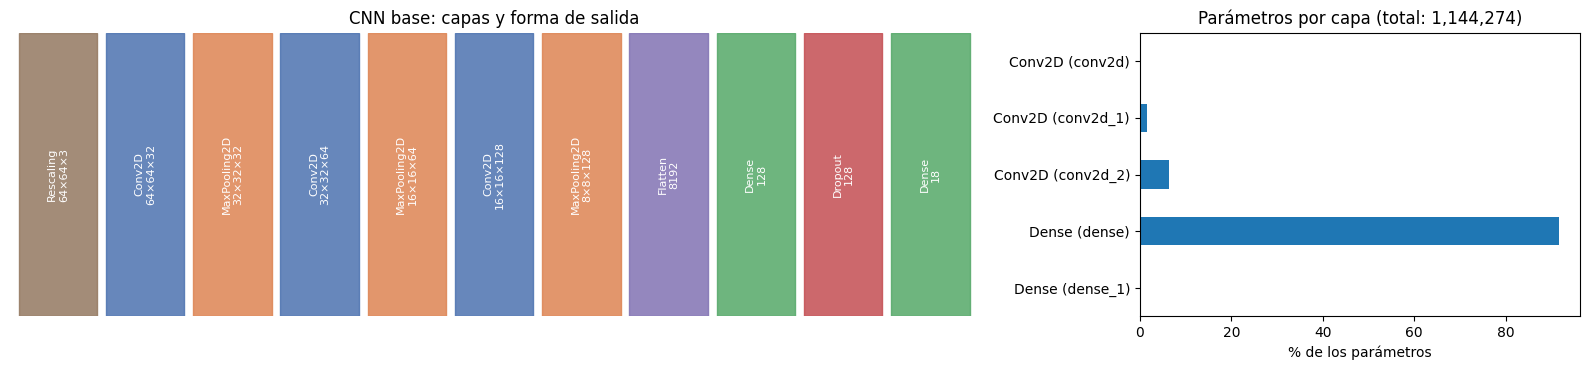

In [15]:
def dibujar_arquitectura(modelo, titulo, ax):
    # Dibuja cada capa como un bloque con su forma de salida
    colores = {"Conv2D": "#4C72B0", "MaxPooling2D": "#DD8452", "Dense": "#55A868", "Dropout": "#C44E52",
               "Flatten": "#8172B3", "Rescaling": "#937860", "BatchNormalization": "#DA8BC3",
               "GlobalAveragePooling2D": "#8C8C8C", "Activation": "#CCB974"}
    capas = [c for c in modelo.layers if not isinstance(c, layers.InputLayer)]
    for i, capa in enumerate(capas):
        tipo = type(capa).__name__
        forma = "×".join(str(d) for d in capa.output.shape[1:])
        ax.add_patch(plt.Rectangle((i, 0), 0.9, 1, color=colores.get(tipo, "#64B5CD"), alpha=0.85))
        ax.text(i + 0.45, 0.5, f"{tipo}\n{forma}", ha="center", va="center", rotation=90, fontsize=8, color="white")
    ax.set_xlim(-0.1, len(capas)); ax.set_ylim(0, 1); ax.axis("off"); ax.set_title(titulo)


fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
dibujar_arquitectura(modelo_base, "CNN base: capas y forma de salida", axes[0])

parametros = pd.Series({f"{type(c).__name__} ({c.name})": c.count_params() for c in modelo_base.layers if c.count_params() > 0})
(parametros / parametros.sum() * 100).plot(kind="barh", ax=axes[1], color="tab:blue")
axes[1].set_xlabel("% de los parámetros"); axes[1].set_title(f"Parámetros por capa (total: {parametros.sum():,})")
axes[1].invert_yaxis()
plt.tight_layout()
guardar_figura("03_arquitectura_cnn_base")
plt.show()

### 4. Entrenamiento y ajuste de hiperparámetros

#### 4.1 Estrategia experimental

Se aplica un **análisis de un factor a la vez** (*one-factor-at-a-time*): se parte de la configuración base (E1) y en cada experimento **se cambia un solo hiperparámetro**, de modo que la diferencia de rendimiento pueda atribuirse a ese cambio. Todos los experimentos usan la misma semilla, el mismo *split* y se comparan **sobre validación** (el *test* no se toca).

Mecanismos comunes de entrenamiento:

- **`EarlyStopping`** (monitorea `val_loss`, restaura los mejores pesos): detiene el entrenamiento cuando el modelo deja de generalizar, evitando sobreajuste y tiempo de cómputo inútil.
- **`ModelCheckpoint`**: guarda el mejor modelo en `resultados/`.
- **`ReduceLROnPlateau`** (en los modelos finales): baja la tasa de aprendizaje a la mitad cuando la validación se estanca, permitiendo un ajuste más fino.

| Exp. | Cambio respecto a E1 | Hipótesis |
|---|---|---|
| **E1** | Base: Adam, `lr=1e-3`, batch 64, dropout 0.5 | Referencia |
| **E2** | `lr = 1e-2` | Pasos demasiado grandes → entrenamiento inestable / divergente |
| **E3** | `lr = 1e-4` | Pasos pequeños → convergencia lenta en el mismo número de épocas |
| **E4** | Optimizador **SGD + momentum 0.9** (`lr=1e-2`) | Sin tasa adaptativa: suele converger más lento que Adam |
| **E5** | Sin dropout (`dropout = 0`) | Más sobreajuste (brecha train–val mayor) |
| **E6** | `batch_size = 256` | Menos actualizaciones por época; gradiente más suave pero convergencia más lenta |
| **E7** | **+ Data augmentation** (más épocas) | Menos sobreajuste y mejor generalización |
| **E8** | + Data augmentation **+ pesos de clase** | Mejor *recall* en personajes con pocas imágenes → mejor F1-macro |

In [16]:
# ---------------- Hiperparámetros globales (centralizados) ----------------
BATCH_SIZE    = 64      # tamaño de lote base
EPOCAS_HP     = 12      # máximo de épocas en los experimentos E1-E6 (con EarlyStopping)
PACIENCIA_HP  = 4       # épocas sin mejorar val_loss antes de detenerse
EPOCAS_AUM    = 25      # con data augmentation el modelo necesita más épocas para converger
PACIENCIA_AUM = 6

RESULTADOS = {}         # nombre del experimento -> historia, métricas de validación, tiempos, etc.


def crear_optimizador(nombre, lr):
    if nombre == "adam":
        return optimizers.Adam(learning_rate=lr)
    if nombre == "sgd":
        return optimizers.SGD(learning_rate=lr, momentum=0.9)
    if nombre == "rmsprop":
        return optimizers.RMSprop(learning_rate=lr)
    raise ValueError(nombre)


def metricas(y_true, probs):
    # Calcula las métricas de clasificación a partir de las probabilidades predichas
    probs = probs.astype("float64")
    probs = probs / probs.sum(axis=1, keepdims=True)
    y_pred = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"loss": log_loss(y_true, probs, labels=np.arange(NUM_CLASSES)),
            "accuracy": accuracy_score(y_true, y_pred),
            "precision_macro": p, "recall_macro": r, "f1_macro": f1,
            "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0)}


def registrar(nombre, predecir, info, descripcion, img_size, params, entrenables, framework="Keras"):
    # Evalúa el modelo sobre validación y guarda todo en RESULTADOS
    X_v, y_v = DATOS[img_size]["val"]
    t0 = time.time()
    probs = predecir(X_v)
    ms_img = (time.time() - t0) / len(X_v) * 1000
    RESULTADOS[nombre] = {"descripcion": descripcion, "predecir": predecir, "historia": info["historia"],
                          "tiempo_s": info["tiempo_s"], "epocas": len(info["historia"]["loss"]),
                          "img_size": img_size, "params": params, "entrenables": entrenables,
                          "framework": framework, "ms_por_imagen": ms_img, "val": metricas(y_v, probs)}
    v = RESULTADOS[nombre]["val"]
    print(f"[{nombre}] val_loss={v['loss']:.4f} | val_accuracy={v['accuracy']:.4f} | "
          f"val_F1_macro={v['f1_macro']:.4f} | {RESULTADOS[nombre]['epocas']} épocas en {info['tiempo_s']/60:.1f} min")


def entrenar_experimento(nombre, construir, descripcion, img_size=IMG_SIZE, optimizador="adam", lr=1e-3,
                         batch_size=BATCH_SIZE, epocas=EPOCAS_HP, paciencia=PACIENCIA_HP,
                         class_weight=None, reducir_lr=False):
    # Construye, compila y entrena un modelo Keras (o lo carga si ya fue entrenado) y lo registra
    ruta_modelo = os.path.join(DIR_RESULTADOS, f"{nombre}.keras")
    ruta_info = os.path.join(DIR_RESULTADOS, f"{nombre}.json")
    (X_t, y_t), (X_v, y_v) = DATOS[img_size]["train"], DATOS[img_size]["val"]

    if REUTILIZAR_RESULTADOS and os.path.exists(ruta_modelo) and os.path.exists(ruta_info):
        print(f"[{nombre}] cargado desde disco (ya había sido entrenado).")
        with open(ruta_info) as f:
            info = json.load(f)
    else:
        fijar_semillas()
        modelo = construir()
        modelo.compile(optimizer=crear_optimizador(optimizador, lr),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True),
               callbacks.ModelCheckpoint(ruta_modelo, monitor="val_loss", save_best_only=True)]
        if reducir_lr:
            cbs.append(callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1))
        print(f"=== Entrenando {nombre}: {descripcion} ===")
        t0 = time.time()
        h = modelo.fit(crear_dataset(X_t, y_t, batch_size, entrenamiento=True),
                       validation_data=crear_dataset(X_v, y_v, 256),
                       epochs=epocas, class_weight=class_weight, callbacks=cbs, verbose=2)
        info = {"historia": {k: [float(v) for v in vals] for k, vals in h.history.items()},
                "tiempo_s": time.time() - t0}
        with open(ruta_info, "w") as f:
            json.dump(info, f)

    modelo = keras.models.load_model(ruta_modelo)          # mejor modelo según val_loss
    entrenables = int(sum(np.prod(w.shape) for w in modelo.trainable_weights))
    registrar(nombre, lambda X, m=modelo: m.predict(X, batch_size=256, verbose=0), info, descripcion,
              img_size, modelo.count_params(), entrenables)
    return modelo


def graficar_curvas(nombres, titulo, archivo=None, ylim_loss=3.2):
    # Curvas de loss y accuracy (entrenamiento punteado, validación continuo)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
    for i, n in enumerate(nombres):
        h = RESULTADOS[n]["historia"]
        ep = np.arange(1, len(h["loss"]) + 1)
        axes[0].plot(ep, h["loss"], "--", color=f"C{i}", alpha=0.55)
        axes[0].plot(ep, h["val_loss"], "-", color=f"C{i}", label=n, lw=2)
        axes[1].plot(ep, h["accuracy"], "--", color=f"C{i}", alpha=0.55)
        axes[1].plot(ep, h["val_accuracy"], "-", color=f"C{i}", label=n, lw=2)
    axes[0].set(title="Loss  (- - entrenamiento | — validación)", xlabel="época", ylabel="loss", ylim=(0, ylim_loss))
    axes[1].set(title="Accuracy  (- - entrenamiento | — validación)", xlabel="época", ylabel="accuracy", ylim=(0, 1))
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout()
    if archivo:
        guardar_figura(archivo)
    plt.show()


def tabla_resultados(nombres):
    # Tabla resumen: tiempo, métricas de validación y brecha de sobreajuste
    filas = []
    for n in nombres:
        r = RESULTADOS[n]; h = r["historia"]; mejor = int(np.argmin(h["val_loss"]))
        filas.append({"experimento": n, "descripción": r["descripcion"], "framework": r["framework"],
                      "img": r["img_size"], "parámetros": r["params"], "épocas": r["epocas"],
                      "mejor época": mejor + 1, "tiempo (min)": r["tiempo_s"] / 60,
                      "s/época": r["tiempo_s"] / r["epocas"], "ms/img (inferencia)": r["ms_por_imagen"],
                      "train acc": h["accuracy"][mejor], "val loss": r["val"]["loss"],
                      "val accuracy": r["val"]["accuracy"], "val precision (macro)": r["val"]["precision_macro"],
                      "val recall (macro)": r["val"]["recall_macro"], "val F1 macro": r["val"]["f1_macro"],
                      "brecha train-val acc": h["accuracy"][mejor] - h["val_accuracy"][mejor]})
    return pd.DataFrame(filas).set_index("experimento")

#### 4.2 Ejecución de los experimentos E1–E8

Cada experimento imprime una línea por época (*loss* y *accuracy* de entrenamiento y validación) y al final las métricas sobre validación.

In [17]:
EXPERIMENTOS_HP = [
    dict(nombre="E1_base",          descripcion="Adam lr=1e-3, batch 64, dropout 0.5",
         construir=lambda: construir_cnn_simple(dropout=0.5)),
    dict(nombre="E2_lr_1e-2",       descripcion="lr alto = 1e-2", lr=1e-2,
         construir=lambda: construir_cnn_simple(dropout=0.5)),
    dict(nombre="E3_lr_1e-4",       descripcion="lr bajo = 1e-4", lr=1e-4,
         construir=lambda: construir_cnn_simple(dropout=0.5)),
    dict(nombre="E4_sgd_momentum",  descripcion="SGD + momentum 0.9, lr=1e-2", optimizador="sgd", lr=1e-2,
         construir=lambda: construir_cnn_simple(dropout=0.5)),
    dict(nombre="E5_sin_dropout",   descripcion="dropout = 0",
         construir=lambda: construir_cnn_simple(dropout=0.0)),
    dict(nombre="E6_batch_256",     descripcion="batch size = 256", batch_size=256,
         construir=lambda: construir_cnn_simple(dropout=0.5)),
    dict(nombre="E7_aumentacion",   descripcion="+ data augmentation", epocas=EPOCAS_AUM, paciencia=PACIENCIA_AUM,
         construir=lambda: construir_cnn_simple(dropout=0.5, aumentacion=True)),
    dict(nombre="E8_aum_pesos",     descripcion="+ data augmentation + pesos de clase", epocas=EPOCAS_AUM,
         paciencia=PACIENCIA_AUM, class_weight=CLASS_WEIGHT,
         construir=lambda: construir_cnn_simple(dropout=0.5, aumentacion=True)),
]

for exp in EXPERIMENTOS_HP:
    entrenar_experimento(**exp)

=== Entrenando E1_base: Adam lr=1e-3, batch 64, dropout 0.5 ===
Epoch 1/12


253/253 - 26s - 105ms/step - accuracy: 0.2824 - loss: 2.3208 - val_accuracy: 0.5419 - val_loss: 1.5663


Epoch 2/12


253/253 - 24s - 93ms/step - accuracy: 0.5080 - loss: 1.6234 - val_accuracy: 0.6479 - val_loss: 1.2130


Epoch 3/12


253/253 - 24s - 94ms/step - accuracy: 0.6111 - loss: 1.2741 - val_accuracy: 0.7009 - val_loss: 1.0367


... (228 outputs left out)

253/253 - 27s - 108ms/step - accuracy: 0.8637 - loss: 0.4016 - val_accuracy: 0.8891 - val_loss: 0.3926


Epoch 25/25


253/253 - 28s - 109ms/step - accuracy: 0.8729 - loss: 0.3658 - val_accuracy: 0.8972 - val_loss: 0.3566


[E8_aum_pesos] val_loss=0.3566 | val_accuracy=0.8972 | val_F1_macro=0.8986 | 25 épocas en 11.5 min


#### 4.3 Impacto de cada hiperparámetro: curvas de entrenamiento

Las líneas **punteadas** son entrenamiento y las **continuas** validación. Una brecha creciente entre ambas indica **sobreajuste**; una curva de validación plana o errática indica problemas de **optimización**.

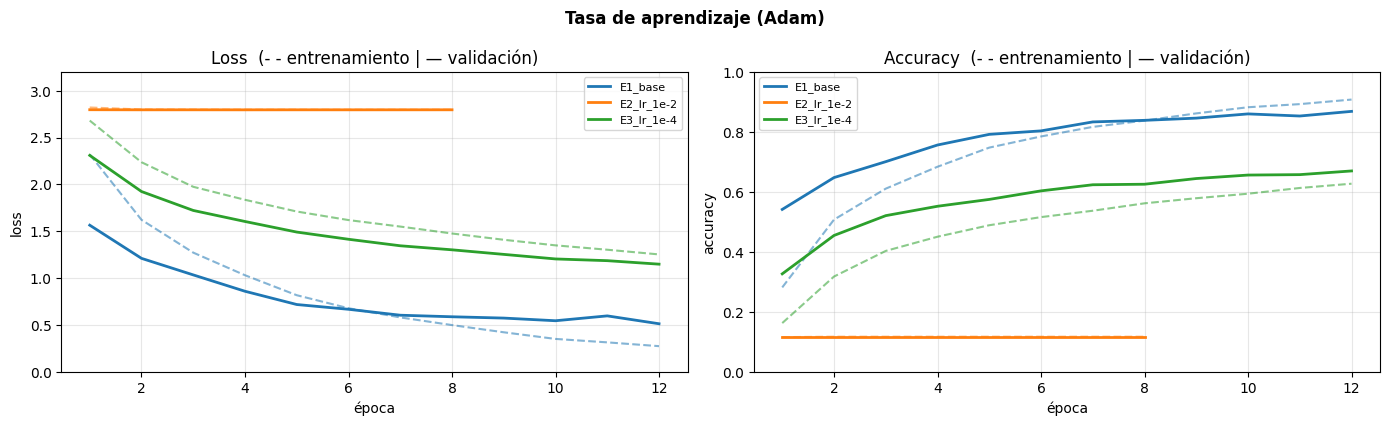

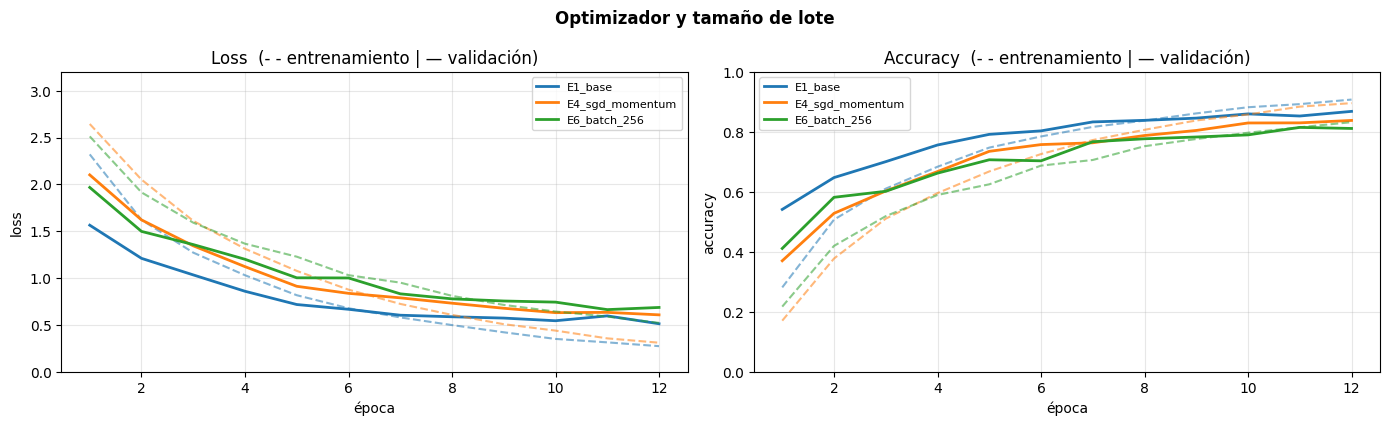

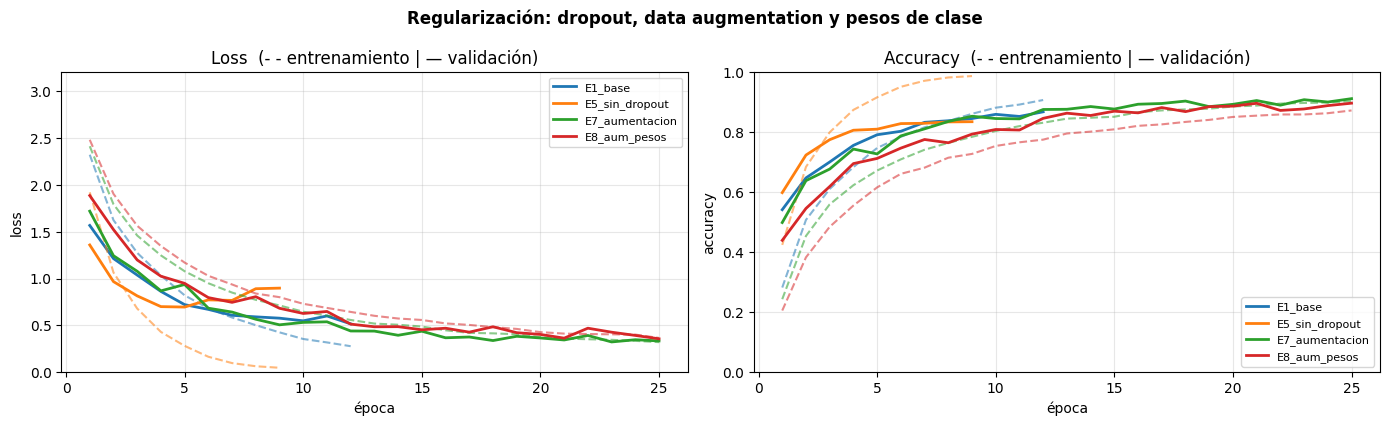

In [18]:
graficar_curvas(["E1_base", "E2_lr_1e-2", "E3_lr_1e-4"], "Tasa de aprendizaje (Adam)", "04_hp_learning_rate")
graficar_curvas(["E1_base", "E4_sgd_momentum", "E6_batch_256"], "Optimizador y tamaño de lote", "04_hp_optimizador_batch")
graficar_curvas(["E1_base", "E5_sin_dropout", "E7_aumentacion", "E8_aum_pesos"], "Regularización: dropout, data augmentation y pesos de clase", "04_hp_regularizacion")

#### 4.4 Tabla resumen y comparación de métricas (validación)

,descripción,épocas,mejor época,tiempo (min),s/época,train acc,val loss,val accuracy,val F1 macro,brecha train-val acc
experimento,,,,,,,,,,
E1_base,"Adam lr=1e-3, batch 64, dropout 0.5",12,12,4.8,24.1,0.9077,0.5163,0.8684,0.8669,0.0393
E2_lr_1e-2,lr alto = 1e-2,8,4,3.2,24.0,0.1183,2.7952,0.1183,0.0118,-0.0000
E3_lr_1e-4,lr bajo = 1e-4,12,12,4.8,24.1,0.6276,1.1511,0.6701,0.6505,-0.0425
E4_sgd_momentum,"SGD + momentum 0.9, lr=1e-2",12,12,4.6,23.2,0.8958,0.6112,0.8382,0.8343,0.0576
E5_sin_dropout,dropout = 0,9,5,3.6,24.1,0.9166,0.6953,0.8105,0.8153,0.1062
E6_batch_256,batch size = 256,12,11,4.5,22.6,0.8155,0.6669,0.8150,0.8144,0.0004
E7_aumentacion,+ data augmentation,25,23,11.5,27.6,0.8979,0.3231,0.9087,0.9042,-0.0108
E8_aum_pesos,+ data augmentation + pesos de clase,25,25,11.5,27.6,0.8729,0.3566,0.8972,0.8986,-0.0243


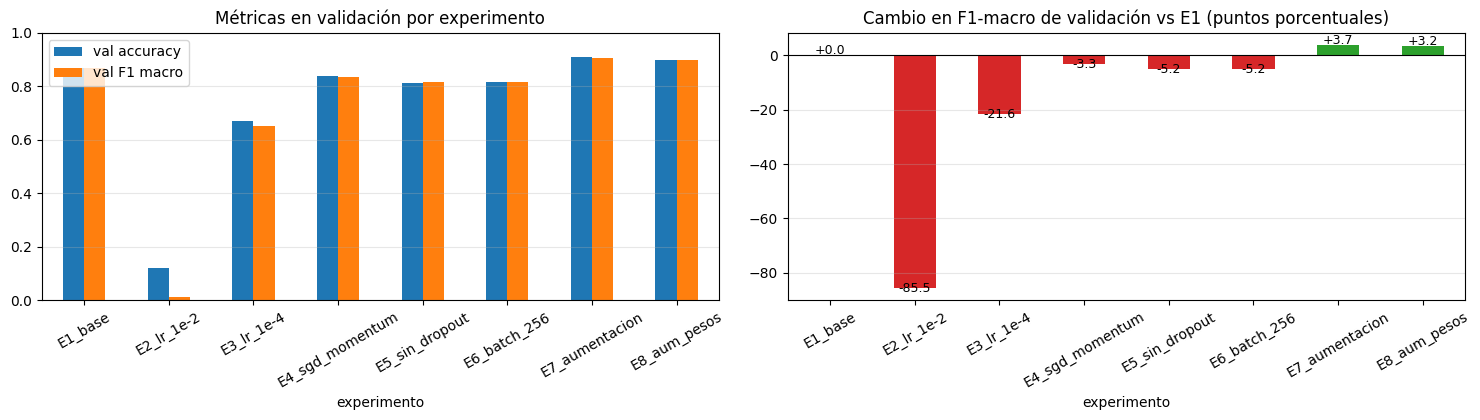

Mejor configuración de la CNN simple: E7_aumentacion
¿Los pesos de clase mejoran el F1-macro? No -> no se usarán en las arquitecturas siguientes


In [19]:
nombres_hp = [e["nombre"] for e in EXPERIMENTOS_HP]
tabla_hp = tabla_resultados(nombres_hp)
cols = ["descripción", "épocas", "mejor época", "tiempo (min)", "s/época", "train acc", "val loss",
        "val accuracy", "val F1 macro", "brecha train-val acc"]
display(tabla_hp[cols].style.format(precision=4, subset=cols[3:]).format(precision=1, subset=["tiempo (min)", "s/época"])
        .highlight_max(subset=["val accuracy", "val F1 macro"], color="#c6efce")
        .highlight_min(subset=["val loss"], color="#c6efce"))
tabla_hp.to_csv(os.path.join(DIR_RESULTADOS, "tabla_hiperparametros.csv"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
tabla_hp[["val accuracy", "val F1 macro"]].plot(kind="bar", ax=axes[0], rot=30, color=["tab:blue", "tab:orange"])
axes[0].set_ylim(0, 1); axes[0].set_title("Métricas en validación por experimento"); axes[0].grid(axis="y", alpha=0.3)
base_f1 = tabla_hp.loc["E1_base", "val F1 macro"]
delta = (tabla_hp["val F1 macro"] - base_f1) * 100
delta.plot(kind="bar", ax=axes[1], rot=30, color=["tab:green" if d >= 0 else "tab:red" for d in delta])
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("Cambio en F1-macro de validación vs E1 (puntos porcentuales)"); axes[1].grid(axis="y", alpha=0.3)
for i, d in enumerate(delta):
    axes[1].text(i, d + (0.5 if d >= 0 else -1.5), f"{d:+.1f}", ha="center", fontsize=9)
plt.tight_layout()
guardar_figura("04_hp_resumen_metricas")
plt.show()

# El mejor experimento de la CNN simple (según F1-macro en validación) pasa a la comparación de arquitecturas
MEJOR_SIMPLE = tabla_hp["val F1 macro"].idxmax()
USAR_PESOS = tabla_hp.loc["E8_aum_pesos", "val F1 macro"] > tabla_hp.loc["E7_aumentacion", "val F1 macro"]
CW_ELEGIDO = CLASS_WEIGHT if USAR_PESOS else None
print(f"Mejor configuración de la CNN simple: {MEJOR_SIMPLE}")
print(f"¿Los pesos de clase mejoran el F1-macro? {'Sí' if USAR_PESOS else 'No'} -> "
      f"{'se usarán' if USAR_PESOS else 'no se usarán'} en las arquitecturas siguientes")

#### 4.5 Análisis de los ajustes de hiperparámetros

**Resumen numérico (validación, 2.849 imágenes):**

| Exp. | Cambio | val accuracy | val F1-macro | Δ F1 vs E1 | val loss | Lectura |
|---|---|---|---|---|---|---|
| E1 | Base | 0,868 | 0,867 | — | 0,516 | Referencia; aún mejorando en la época 12 |
| E2 | `lr = 1e-2` | 0,118 | 0,012 | **−85,5 pp** | 2,795 | **Diverge**: predice siempre "Homer" |
| E3 | `lr = 1e-4` | 0,670 | 0,651 | −21,6 pp | 1,151 | **Sub-ajuste**: converge demasiado lento |
| E4 | SGD + momentum | 0,838 | 0,834 | −3,3 pp | 0,611 | Más lento que Adam con el mismo presupuesto |
| E5 | Sin dropout | 0,811 | 0,815 | −5,2 pp | 0,695 | **Sobreajuste** temprano (mejor época: 5) |
| E6 | Batch 256 | 0,815 | 0,814 | −5,2 pp | 0,667 | 4× menos actualizaciones por época |
| **E7** | **+ Data augmentation** | **0,909** | **0,904** | **+3,7 pp** | **0,323** | **Mejor configuración** |
| E8 | + Aug. + pesos de clase | 0,897 | 0,899 | +3,2 pp | 0,357 | Bueno, pero no supera a E7 |

**1. Tasa de aprendizaje: el hiperparámetro más crítico.**
- Con **`lr = 1e-2` (E2)** el entrenamiento **colapsa**: la *loss* se queda clavada en 2,796 desde la primera época y la *accuracy* en 11,8 %, que es exactamente la proporción de imágenes de Homer (la clase mayoritaria). Los pasos de gradiente son tan grandes que, en las primeras iteraciones, empujan las neuronas ReLU a la zona negativa ("**neuronas ReLU muertas**", gradiente cero): la red deja de aprender y solo devuelve la probabilidad *a priori* de cada clase. Por eso la *loss* coincide con la entropía de la distribución de clases.
- Con **`lr = 1e-4` (E3)** ocurre lo contrario: el aprendizaje es estable pero **10 veces más lento**. Tras 12 épocas llega a 67 % de *accuracy* y la curva de validación sigue subiendo: el modelo está **sub-ajustado** por falta de presupuesto de entrenamiento, no por falta de capacidad.
- **`lr = 1e-3` (E1)** es el punto de equilibrio. Diferencia entre la peor y la mejor tasa: **85 puntos de F1**, lo que muestra que la tasa de aprendizaje puede hacer fracasar o funcionar un modelo con la misma arquitectura.

**2. Optimizador (E4).** SGD con *momentum* 0,9 llega a 83,8 % (−3,3 pp de F1). Adam adapta la tasa de aprendizaje de cada parámetro usando estimaciones del primer y segundo momento del gradiente, por lo que converge más rápido con el mismo número de épocas. SGD suele igualar o superar a Adam en generalización, pero necesita más épocas y una buena programación de la tasa de aprendizaje; con un presupuesto limitado (relevante en CPU) **Adam es la opción más eficiente**.

**3. Dropout (E5): evidencia directa de sobreajuste.** Sin *dropout*, la *accuracy* de entrenamiento sube a **98,8 %** mientras la de validación se estanca en ~83 % y la *loss* de validación **empieza a subir desde la época 5** (0,695 → 0,897). La brecha entrenamiento-validación en la mejor época es de **10,6 pp**, frente a 3,9 pp en E1. Esto confirma el diagnóstico de la sección 3: la capa `Dense` con ~1 M de parámetros memoriza las imágenes de entrenamiento si no se regulariza. El *EarlyStopping* evitó entregar el modelo sobreajustado, porque restauró los pesos de la época 5.

**4. Tamaño de lote (E6).** Con *batch* 256 cada época tiene 64 actualizaciones de pesos en vez de 253 (16.143 / 64). Con la misma tasa de aprendizaje el modelo avanza más lento por época (−5,2 pp de F1) y **en CPU el tiempo por época solo baja 6 %** (22,6 s vs 24,1 s), así que no compensa. Un lote grande solo conviene en GPU y aumentando proporcionalmente la tasa de aprendizaje (regla de escalado lineal, Goyal et al., 2017).

**5. Data augmentation (E7): la mejora más importante.** Al presentar en cada época versiones distintas de cada imagen (volteada, rotada, desplazada, con zoom), el modelo no puede memorizar y aprende rasgos invariantes del personaje:
- F1-macro: **0,867 → 0,904 (+3,7 pp)** y *accuracy* **0,868 → 0,909**.
- *Loss* de validación: **0,516 → 0,323 (−37 %)**: las predicciones no solo aciertan más, también son **más confiables** (mejor calibradas).
- La brecha de sobreajuste desaparece (−1,1 pp; la *accuracy* de entrenamiento se mide sobre imágenes aumentadas y con *dropout* activo, por eso queda bajo la de validación).
- **Costo:** necesita más épocas (mejor época 23 de 25) y cada época es un 15 % más lenta (27,6 s vs 24,1 s).

**6. Pesos de clase (E8).** Dan pesos entre ~0,47 (Homer) y ~2,95 (Nelson). En validación el F1-macro queda **0,6 pp bajo E7** (0,899 vs 0,904) y el *recall* macro también baja (0,894 vs 0,904). Interpretación: incluso la clase más pequeña tiene ~300 imágenes y personajes con rasgos muy distintivos, por lo que el desbalance (6,3×) no es lo bastante severo para que la re-ponderación ayude. En cambio, aumenta la varianza del gradiente y ralentiza la convergencia (su mejor época es la última). **Decisión basada en evidencia:** no se usan pesos de clase en las arquitecturas siguientes.

**Configuración elegida para la CNN simple (E7):** Adam, `lr = 1e-3`, *batch* 64, *dropout* 0,5, *data augmentation*, sin pesos de clase. Este conjunto de hiperparámetros (tasa de aprendizaje, *batch*, *augmentation*) se mantiene en los modelos de la sección 5.

### 5. Comparación de arquitecturas y herramientas

Se comparan, con el **mismo *split*** y las **mismas métricas de validación**:

| Modelo | Tipo | Idea principal |
|---|---|---|
| **CNN simple ajustada** | Desde cero (3 conv) | Mejor configuración de la sección 4 |
| **CNN profunda** | Desde cero, estilo VGG (8 conv) + *BatchNormalization* + *GlobalAveragePooling* | Más capacidad para patrones complejos, con mejor regularización |
| **MobileNetV2 – extracción de características** | *Transfer learning* (ImageNet), base congelada | Reutiliza filtros aprendidos con 1,2 M de imágenes; solo se entrena el clasificador |
| **MobileNetV2 – *fine-tuning*** | *Transfer learning*, últimas capas descongeladas | Adapta los filtros de alto nivel al dominio "dibujo animado" |
| **CNN simple en PyTorch** | Misma arquitectura e hiperparámetros que E1 | Comparación de **herramientas** (Keras vs PyTorch) |

In [20]:
EPOCAS_PROFUNDA, PACIENCIA_PROFUNDA = 20, 6
EPOCAS_TL_FASE1, PACIENCIA_TL_FASE1 = 6, 3
EPOCAS_TL_FASE2, PACIENCIA_TL_FASE2 = 12, 4

#### 5.1 CNN profunda (estilo VGG + BatchNormalization + GlobalAveragePooling)

Mejoras de diseño respecto a la CNN base y su justificación:

1. **Dos convoluciones 3×3 por bloque** (4 bloques: 32→64→128→256 filtros): dos 3×3 apiladas equivalen a un campo receptivo 5×5 con menos parámetros y una no-linealidad extra. El campo receptivo final (~76 px) cubre la imagen completa.
2. **`BatchNormalization`** tras cada convolución (antes de ReLU, por eso `use_bias=False`): normaliza las activaciones de cada lote, estabiliza y acelera el entrenamiento y permite tasas de aprendizaje mayores (Ioffe & Szegedy, 2015).
3. **`GlobalAveragePooling2D`** en vez de `Flatten`: promedia cada mapa de características → 256 valores en lugar de 8.192. El clasificador pasa de ~1 M a ~66 mil parámetros, reduciendo drásticamente el sobreajuste (Lin et al., 2014, *Network in Network*).
4. **Dropout 0.4 + regularización L2 (1e-4)** en la capa densa, **data augmentation** y `ReduceLROnPlateau`.

A pesar de tener 8 capas convolucionales, el modelo tiene **una cantidad de parámetros similar** a la CNN base: la capacidad se invierte en extraer características, no en memorizar.

In [21]:
def bloque_conv(modelo, filtros):
    # Bloque VGG: 2 x (Conv 3x3 -> BatchNorm -> ReLU) + MaxPool 2x2
    for _ in range(2):
        modelo.add(layers.Conv2D(filtros, 3, padding="same", use_bias=False))
        modelo.add(layers.BatchNormalization())
        modelo.add(layers.Activation("relu"))
    modelo.add(layers.MaxPooling2D(2))


def construir_cnn_profunda(img_size=IMG_SIZE, nombre="cnn_profunda"):
    modelo = keras.Sequential(name=nombre)
    modelo.add(layers.Input(shape=(img_size, img_size, 3)))
    modelo.add(crear_aumentacion())
    modelo.add(layers.Rescaling(1.0 / 255))
    for filtros in (32, 64, 128, 256):
        bloque_conv(modelo, filtros)
    modelo.add(layers.GlobalAveragePooling2D())
    modelo.add(layers.Dropout(0.4))
    modelo.add(layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-4)))
    modelo.add(layers.Dropout(0.4))
    modelo.add(layers.Dense(NUM_CLASSES, activation="softmax"))
    return modelo


construir_cnn_profunda().summary()

modelo_profundo = entrenar_experimento(
    "cnn_profunda", construir_cnn_profunda,
    descripcion="VGG-style 8 conv + BN + GAP + aug" + (" + pesos" if USAR_PESOS else ""),
    epocas=EPOCAS_PROFUNDA, paciencia=PACIENCIA_PROFUNDA, class_weight=CW_ELEGIDO, reducir_lr=True)

Model: "cnn_profunda"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_10 (Rescaling)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 16, 16, 128)    │             

 Total params: 1,245,554 (4.75 MB)

 Trainable params: 1,243,634 (4.74 MB)

 Non-trainable params: 1,920 (7.50 KB)

=== Entrenando cnn_profunda: VGG-style 8 conv + BN + GAP + aug ===
Epoch 1/20


... (39 outputs left out)

253/253 - 134s - 529ms/step - accuracy: 0.9560 - loss: 0.1772 - val_accuracy: 0.9151 - val_loss: 0.3669 - learning_rate: 2.5000e-04


Epoch 20/20


253/253 - 138s - 544ms/step - accuracy: 0.9654 - loss: 0.1453 - val_accuracy: 0.9442 - val_loss: 0.2419 - learning_rate: 1.2500e-04


[cnn_profunda] val_loss=0.2186 | val_accuracy=0.9442 | val_F1_macro=0.9426 | 20 épocas en 45.7 min


#### 5.2 *Transfer learning* con MobileNetV2 (pre-entrenada en ImageNet)

**¿Por qué MobileNetV2?** Es una arquitectura moderna con **bloques residuales invertidos** (conexiones residuales como ResNet) y **convoluciones separables en profundidad**, que reducen el costo ~8-9 veces frente a convoluciones estándar. Con ~2,3 M de parámetros es mucho más liviana que ResNet50 (~25 M) o VGG16 (~138 M), lo que la hace entrenable incluso sin GPU y adecuada para desplegar en dispositivos modestos.

**Procedimiento en dos fases** (práctica recomendada por la documentación de Keras):

1. **Extracción de características:** la base convolucional se **congela** y solo se entrena un clasificador nuevo (`GlobalAveragePooling → Dropout(0.3) → Dense(18)`) con `lr = 1e-3`.
2. ***Fine-tuning*:** se descongelan las capas desde la 100 en adelante (los bloques de alto nivel) y se re-entrena con **`lr = 1e-4`** (10 veces menor) para ajustar los filtros al dominio de dibujos animados sin destruir lo aprendido. Las capas `BatchNormalization` se mantienen en modo inferencia (`training=False`).

**Preprocesamiento específico:** MobileNetV2 espera píxeles en **[-1, 1]**, por eso se usa `Rescaling(1/127.5, offset=-1)` y entrada de **96×96** (resolución mínima con pesos pre-entrenados). Se cargan las mismas imágenes a 96×96 y se reutilizan **exactamente los mismos índices** de entrenamiento/validación.

In [22]:
IMG_SIZE_TL = 96
X_train96, y_train96, _ = cargar_imagenes(DIR_TRAIN, img_size=IMG_SIZE_TL)
X_test96,  y_test96,  _ = cargar_imagenes(DIR_TEST,  img_size=IMG_SIZE_TL)
assert (y_train96 == y_train).all() and (y_test96 == y_test).all()      # mismo orden de archivos

DATOS[IMG_SIZE_TL] = {"train": (X_train96[idx_tr], y_tr), "val": (X_train96[idx_val], y_val),
                      "test": (X_test96, y_test)}


def construir_mobilenet(img_size=IMG_SIZE_TL):
    base = keras.applications.MobileNetV2(input_shape=(img_size, img_size, 3), include_top=False, weights="imagenet")
    base.trainable = False                                   # fase 1: base congelada
    entrada = layers.Input(shape=(img_size, img_size, 3))
    x = crear_aumentacion()(entrada)
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)          # 0-255 -> [-1, 1]
    x = base(x, training=False)                              # BatchNorm de la base en modo inferencia
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(entrada, salida, name="mobilenetv2_tl")


def base_mobilenet(modelo):
    return next(c for c in modelo.layers if c.name.startswith("mobilenetv2"))


def preparar_fine_tuning(capa_inicio=100):
    # Carga el modelo de la fase 1 y descongela las capas de alto nivel de la base
    modelo = keras.models.load_model(os.path.join(DIR_RESULTADOS, "mobilenetv2_extraccion.keras"))
    base = base_mobilenet(modelo)
    base.trainable = True
    for capa in base.layers[:capa_inicio]:
        capa.trainable = False
    return modelo


# ---- Fase 1: extracción de características ----
entrenar_experimento("mobilenetv2_extraccion", construir_mobilenet, img_size=IMG_SIZE_TL,
                     descripcion="MobileNetV2 ImageNet, base congelada", lr=1e-3,
                     epocas=EPOCAS_TL_FASE1, paciencia=PACIENCIA_TL_FASE1, class_weight=CW_ELEGIDO)

# ---- Fase 2: fine-tuning ----
modelo_mnv2 = entrenar_experimento("mobilenetv2_finetuning", preparar_fine_tuning, img_size=IMG_SIZE_TL,
                                   descripcion="MobileNetV2 fine-tuning (capas 100+)", lr=1e-4,
                                   epocas=EPOCAS_TL_FASE2, paciencia=PACIENCIA_TL_FASE2,
                                   class_weight=CW_ELEGIDO, reducir_lr=True)
base_ft = base_mobilenet(modelo_mnv2)
print(f"Capas de la base: {len(base_ft.layers)} | entrenables en fine-tuning: "
      f"{sum(c.trainable for c in base_ft.layers)} | parámetros entrenables: {RESULTADOS['mobilenetv2_finetuning']['entrenables']:,}")

# Historia combinada de ambas fases (para graficar el efecto del fine-tuning)
h1, h2 = RESULTADOS["mobilenetv2_extraccion"]["historia"], RESULTADOS["mobilenetv2_finetuning"]["historia"]
RESULTADOS["mobilenetv2_finetuning"]["historia_completa"] = {k: h1[k] + h2[k] for k in ("loss", "val_loss", "accuracy", "val_accuracy")}

simpsons_train: 18992 imágenes cargadas (0 omitidas)


simpsons_test: 890 imágenes cargadas (0 omitidas)


=== Entrenando mobilenetv2_extraccion: MobileNetV2 ImageNet, base congelada ===


Epoch 1/6


253/253 - 58s - 230ms/step - accuracy: 0.3885 - loss: 2.0879 - val_accuracy: 0.5999 - val_loss: 1.3388


Epoch 2/6


... (32 outputs left out)

253/253 - 78s - 307ms/step - accuracy: 0.9623 - loss: 0.1231 - val_accuracy: 0.9094 - val_loss: 0.3768 - learning_rate: 1.0000e-04


Epoch 12/12


253/253 - 79s - 313ms/step - accuracy: 0.9687 - loss: 0.1014 - val_accuracy: 0.9214 - val_loss: 0.3488 - learning_rate: 5.0000e-05


[mobilenetv2_finetuning] val_loss=0.3488 | val_accuracy=0.9214 | val_F1_macro=0.9176 | 12 épocas en 16.2 min
Capas de la base: 154 | entrenables en fine-tuning: 55 | parámetros entrenables: 1,884,498


#### 5.3 Comparación de herramientas: la CNN base en **PyTorch**

Para comparar **herramientas** (y no arquitecturas) se re-implementa en PyTorch **exactamente la CNN base E1**: mismas capas, Adam `lr=1e-3`, batch 64, dropout 0.5, máximo 12 épocas con *early stopping* (paciencia 4) y el mismo *split*. Diferencias de implementación que hay que tener presentes:

- En PyTorch el **ciclo de entrenamiento se escribe a mano** (*forward*, `loss.backward()`, `optimizer.step()`, validación, *early stopping* y guardado del mejor modelo).
- Las imágenes deben pasar de formato **NHWC** (Keras) a **NCHW** (PyTorch).
- `nn.CrossEntropyLoss` incluye el *softmax*, por lo que la red devuelve *logits*.
- La **inicialización de pesos por defecto difiere** (Keras: Glorot uniforme; PyTorch: Kaiming uniforme), lo que puede explicar pequeñas diferencias de rendimiento.

In [23]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | dispositivo: {DISPOSITIVO}")


class CNNSimpleTorch(nn.Module):
    # Misma arquitectura que la CNN base de Keras (E1)
    def __init__(self, num_clases=NUM_CLASSES, dropout=0.5, img_size=IMG_SIZE):
        super().__init__()
        self.extractor = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.clasificador = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * (img_size // 8) ** 2, 128), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(128, num_clases))       # logits (softmax va en la pérdida)

    def forward(self, x):
        return self.clasificador(self.extractor(x))


def a_tensor(X):
    # NHWC uint8 (0-255) -> NCHW float32 (0-1)
    return torch.from_numpy(X).permute(0, 3, 1, 2).float().div(255.0)


def predecir_torch(modelo, X, lote=512):
    modelo.eval()
    salidas = []
    with torch.no_grad():
        for i in range(0, len(X), lote):
            salidas.append(torch.softmax(modelo(a_tensor(X[i:i + lote]).to(DISPOSITIVO)), dim=1).cpu().numpy())
    return np.concatenate(salidas)


def entrenar_pytorch(nombre="pytorch_cnn_simple", epocas=EPOCAS_HP, paciencia=PACIENCIA_HP, lr=1e-3, batch_size=BATCH_SIZE):
    ruta_pesos = os.path.join(DIR_RESULTADOS, f"{nombre}.pt")
    ruta_info = os.path.join(DIR_RESULTADOS, f"{nombre}.json")
    torch.manual_seed(SEED)
    modelo = CNNSimpleTorch().to(DISPOSITIVO)

    if REUTILIZAR_RESULTADOS and os.path.exists(ruta_pesos) and os.path.exists(ruta_info):
        print(f"[{nombre}] cargado desde disco (ya había sido entrenado).")
        modelo.load_state_dict(torch.load(ruta_pesos, map_location=DISPOSITIVO))
        with open(ruta_info) as f:
            info = json.load(f)
    else:
        cargador = DataLoader(TensorDataset(a_tensor(X_tr), torch.from_numpy(y_tr).long()), batch_size=batch_size,
                              shuffle=True, generator=torch.Generator().manual_seed(SEED))
        Xv_t, yv_t = a_tensor(X_val), torch.from_numpy(y_val).long()
        optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
        criterio = nn.CrossEntropyLoss()
        historia = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
        mejor_loss, espera, mejor_estado = np.inf, 0, None
        print(f"=== Entrenando {nombre} (PyTorch) ===")
        t0 = time.time()
        for epoca in range(1, epocas + 1):
            t_ep = time.time()
            modelo.train()                                    # activa dropout
            suma_loss, aciertos, n = 0.0, 0, 0
            for xb, yb in cargador:
                xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
                optimizador.zero_grad()                       # 1) limpia gradientes
                logits = modelo(xb)                           # 2) forward
                loss = criterio(logits, yb)
                loss.backward()                               # 3) backpropagation
                optimizador.step()                            # 4) actualiza pesos
                suma_loss += loss.item() * len(yb)
                aciertos += (logits.argmax(1) == yb).sum().item()
                n += len(yb)
            modelo.eval()                                     # validación (sin dropout ni gradientes)
            with torch.no_grad():
                logits_v = torch.cat([modelo(Xv_t[i:i + 512].to(DISPOSITIVO)).cpu() for i in range(0, len(Xv_t), 512)])
                val_loss = criterio(logits_v, yv_t).item()
                val_acc = (logits_v.argmax(1) == yv_t).float().mean().item()
            historia["loss"].append(suma_loss / n); historia["accuracy"].append(aciertos / n)
            historia["val_loss"].append(val_loss); historia["val_accuracy"].append(val_acc)
            print(f"Epoch {epoca}/{epocas} - {time.time() - t_ep:.0f}s - loss: {suma_loss / n:.4f} - accuracy: {aciertos / n:.4f}"
                  f" - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")
            if val_loss < mejor_loss:                         # early stopping manual
                mejor_loss, espera, mejor_estado = val_loss, 0, copy.deepcopy(modelo.state_dict())
            else:
                espera += 1
                if espera >= paciencia:
                    print(f"Early stopping en la época {epoca}")
                    break
        modelo.load_state_dict(mejor_estado)                  # restaura los mejores pesos
        info = {"historia": historia, "tiempo_s": time.time() - t0}
        torch.save(modelo.state_dict(), ruta_pesos)
        with open(ruta_info, "w") as f:
            json.dump(info, f)

    params = sum(p.numel() for p in modelo.parameters())
    registrar(nombre, lambda X, m=modelo: predecir_torch(m, X), info, "Misma CNN que E1, en PyTorch",
              IMG_SIZE, params, params, framework="PyTorch")
    return modelo


modelo_torch = entrenar_pytorch()

PyTorch 2.11.0+cpu | dispositivo: cpu


=== Entrenando pytorch_cnn_simple (PyTorch) ===


Epoch 1/12 - 49s - loss: 2.2921 - accuracy: 0.2884 - val_loss: 1.6340 - val_accuracy: 0.5290


Epoch 2/12 - 49s - loss: 1.6137 - accuracy: 0.5107 - val_loss: 1.2026 - val_accuracy: 0.6385


Epoch 3/12 - 47s - loss: 1.2814 - accuracy: 0.6107 - val_loss: 0.9847 - val_accuracy: 0.7132


Epoch 4/12 - 46s - loss: 1.0560 - accuracy: 0.6725 - val_loss: 0.8580 - val_accuracy: 0.7403


... (5 outputs left out)

Epoch 10/12 - 47s - loss: 0.4756 - accuracy: 0.8441 - val_loss: 0.5797 - val_accuracy: 0.8378


Epoch 11/12 - 46s - loss: 0.4184 - accuracy: 0.8611 - val_loss: 0.5840 - val_accuracy: 0.8445


Epoch 12/12 - 45s - loss: 0.3662 - accuracy: 0.8756 - val_loss: 0.6075 - val_accuracy: 0.8420


[pytorch_cnn_simple] val_loss=0.5797 | val_accuracy=0.8378 | val_F1_macro=0.8376 | 12 épocas en 9.5 min


##### Keras vs PyTorch con la misma arquitectura

,framework,parámetros,épocas,mejor época,s/época,ms/img (inferencia),val loss,val accuracy,val F1 macro
experimento,,,,,,,,,
E1_base,Keras,1144274,12,12,24.0880,0.4595,0.5163,0.8684,0.8669
pytorch_cnn_simple,PyTorch,1144274,12,10,47.2882,0.5340,0.5797,0.8378,0.8376


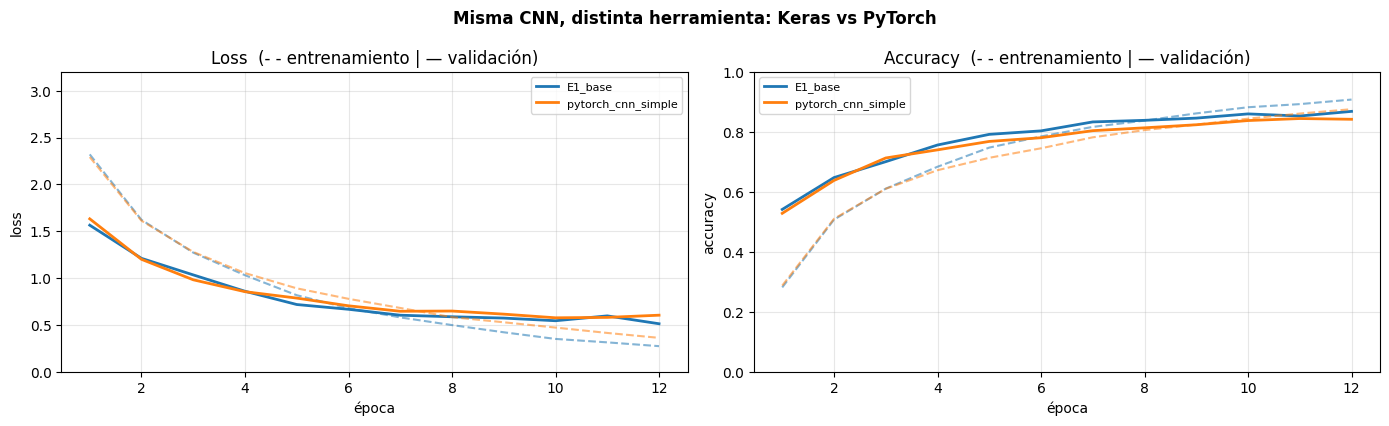

,Keras / TensorFlow,PyTorch
Definir la red,~15 líneas (Sequential),~15 líneas (nn.Module)
Entrenamiento,model.fit() + callbacks,Bucle manual (~30 líneas)
Early stopping / checkpoints,"Incluidos (EarlyStopping, Checkpoint, ReduceLR)",Se programan a mano
Data augmentation,Capas Random* dentro del modelo,torchvision.transforms en el Dataset
Modelos pre-entrenados,keras.applications (1 línea),torchvision.models
Guardado del modelo,Formato .keras (arquitectura + pesos + optimiz...,state_dict (solo pesos; la clase se necesita a...


In [24]:
tabla_herr = tabla_resultados(["E1_base", "pytorch_cnn_simple"])
display(tabla_herr[["framework", "parámetros", "épocas", "mejor época", "s/época", "ms/img (inferencia)",
                    "val loss", "val accuracy", "val F1 macro"]].round(4))
graficar_curvas(["E1_base", "pytorch_cnn_simple"], "Misma CNN, distinta herramienta: Keras vs PyTorch", "05_keras_vs_pytorch")

comparacion_cualitativa = pd.DataFrame({
    "Keras / TensorFlow": ["~15 líneas (Sequential)", "model.fit() + callbacks", "Incluidos (EarlyStopping, Checkpoint, ReduceLR)",
                            "Capas Random* dentro del modelo", "keras.applications (1 línea)", "Formato .keras (arquitectura + pesos + optimizador)"],
    "PyTorch": ["~15 líneas (nn.Module)", "Bucle manual (~30 líneas)", "Se programan a mano",
                "torchvision.transforms en el Dataset", "torchvision.models", "state_dict (solo pesos; la clase se necesita aparte)"],
}, index=["Definir la red", "Entrenamiento", "Early stopping / checkpoints", "Data augmentation",
          "Modelos pre-entrenados", "Guardado del modelo"])
display(comparacion_cualitativa)

#### 5.4 Comparación global de arquitecturas (validación)

,descripción,framework,img,parámetros,épocas,tiempo (min),s/época,ms/img (inferencia),val loss,val accuracy,val precision (macro),val recall (macro),val F1 macro,brecha train-val acc
experimento,,,,,,,,,,,,,,
E7_aumentacion,+ data augmentation,Keras,64,"1,144,274",25,11.5,27.6,0.47,0.3231,0.9087,0.9059,0.9042,0.9042,-0.0108
cnn_profunda,VGG-style 8 conv + BN + GAP + aug,Keras,64,"1,245,554",20,45.7,137.2,1.96,0.2186,0.9442,0.9488,0.9385,0.9426,0.0212
mobilenetv2_extraccion,"MobileNetV2 ImageNet, base congelada",Keras,96,"2,281,042",6,5.3,53.2,3.53,1.0916,0.6774,0.6999,0.6725,0.6767,-0.0442
mobilenetv2_finetuning,MobileNetV2 fine-tuning (capas 100+),Keras,96,"2,281,042",12,16.2,81.0,3.19,0.3488,0.9214,0.9216,0.9168,0.9176,0.0473
E1_base,"Adam lr=1e-3, batch 64, dropout 0.5",Keras,64,"1,144,274",12,4.8,24.1,0.46,0.5163,0.8684,0.8835,0.8551,0.8669,0.0393
pytorch_cnn_simple,"Misma CNN que E1, en PyTorch",PyTorch,64,"1,144,274",12,9.5,47.3,0.53,0.5797,0.8378,0.8496,0.8307,0.8376,0.0062


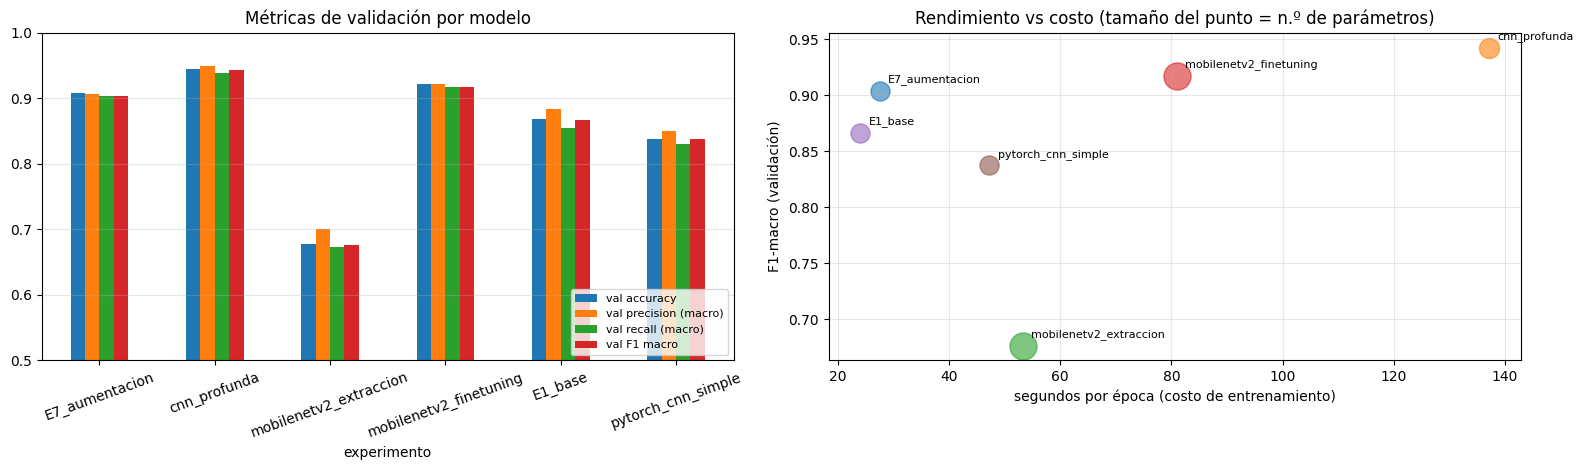

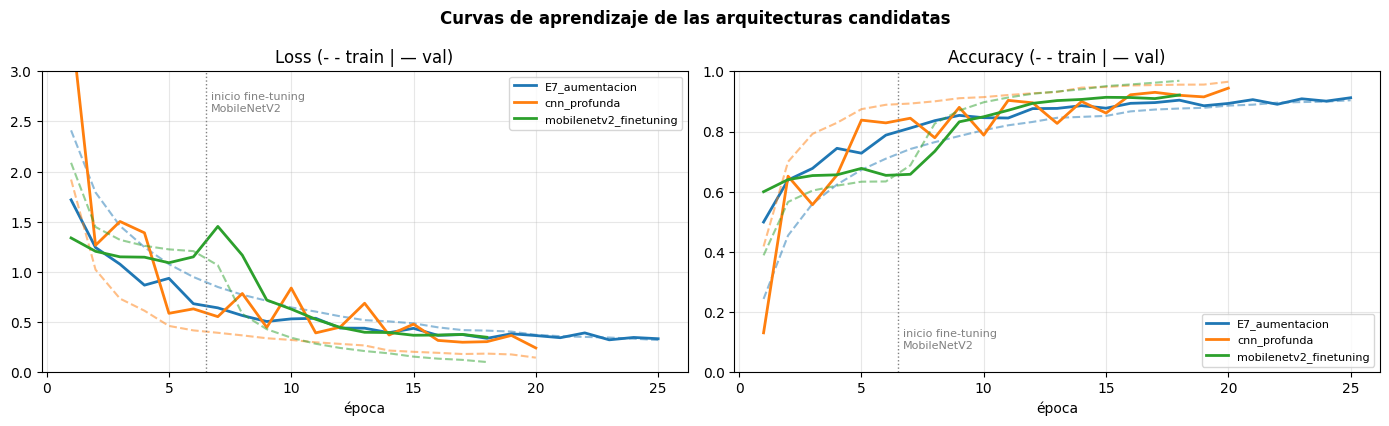

In [25]:
COMPARADOS = [MEJOR_SIMPLE, "cnn_profunda", "mobilenetv2_extraccion", "mobilenetv2_finetuning", "E1_base", "pytorch_cnn_simple"]
COMPARADOS = list(dict.fromkeys(COMPARADOS))          # evita duplicados si MEJOR_SIMPLE fuera E1
tabla_arq = tabla_resultados(COMPARADOS)
cols_arq = ["descripción", "framework", "img", "parámetros", "épocas", "tiempo (min)", "s/época", "ms/img (inferencia)",
            "val loss", "val accuracy", "val precision (macro)", "val recall (macro)", "val F1 macro", "brecha train-val acc"]
display(tabla_arq[cols_arq].style.format(precision=4, subset=cols_arq[8:]).format(precision=1, subset=["tiempo (min)", "s/época"])
        .format(precision=2, subset=["ms/img (inferencia)"]).format("{:,}", subset=["parámetros"])
        .highlight_max(subset=["val accuracy", "val F1 macro"], color="#c6efce").highlight_min(subset=["val loss"], color="#c6efce"))
tabla_arq.to_csv(os.path.join(DIR_RESULTADOS, "tabla_arquitecturas.csv"))

# --- Gráfico 1: métricas de validación por modelo ---
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
tabla_arq[["val accuracy", "val precision (macro)", "val recall (macro)", "val F1 macro"]].plot(kind="bar", ax=axes[0], rot=20)
axes[0].set_ylim(0.5, 1); axes[0].set_title("Métricas de validación por modelo"); axes[0].grid(axis="y", alpha=0.3)
axes[0].legend(loc="lower right", fontsize=8)
# --- Gráfico 2: rendimiento vs costo ---
for i, n in enumerate(tabla_arq.index):
    fila = tabla_arq.loc[n]
    axes[1].scatter(fila["s/época"], fila["val F1 macro"], s=fila["parámetros"] / 6000, alpha=0.6, color=f"C{i}")
    axes[1].annotate(n, (fila["s/época"], fila["val F1 macro"]), fontsize=8, xytext=(6, 6), textcoords="offset points")
axes[1].set(xlabel="segundos por época (costo de entrenamiento)", ylabel="F1-macro (validación)",
            title="Rendimiento vs costo (tamaño del punto = n.º de parámetros)")
axes[1].grid(alpha=0.3)
plt.tight_layout()
guardar_figura("05_comparacion_arquitecturas")
plt.show()

# --- Gráfico 3: curvas de validación ---
RESULTADOS_CURVAS = {n: RESULTADOS[n].get("historia_completa", RESULTADOS[n]["historia"]) for n in [MEJOR_SIMPLE, "cnn_profunda", "mobilenetv2_finetuning"]}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for i, (n, h) in enumerate(RESULTADOS_CURVAS.items()):
    ep = np.arange(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], color=f"C{i}", lw=2, label=n); axes[0].plot(ep, h["loss"], "--", color=f"C{i}", alpha=0.5)
    axes[1].plot(ep, h["val_accuracy"], color=f"C{i}", lw=2, label=n); axes[1].plot(ep, h["accuracy"], "--", color=f"C{i}", alpha=0.5)
axes[0].set(title="Loss (- - train | — val)", xlabel="época", ylim=(0, 3))
axes[1].set(title="Accuracy (- - train | — val)", xlabel="época", ylim=(0, 1))
fase1 = RESULTADOS["mobilenetv2_extraccion"]["epocas"]
for ax, y_txt in zip(axes, (2.6, 0.08)):
    ax.axvline(fase1 + 0.5, color="gray", ls=":", lw=1)
    ax.text(fase1 + 0.7, y_txt, "inicio fine-tuning\nMobileNetV2", fontsize=8, color="gray")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("Curvas de aprendizaje de las arquitecturas candidatas", fontweight="bold")
plt.tight_layout()
guardar_figura("05_curvas_arquitecturas")
plt.show()

#### 5.5 Selección del modelo final

El modelo final se elige **solo con datos de validación**, usando como criterio principal el **F1-macro** (todas las clases pesan lo mismo) y, como desempate, la *loss* de validación (mejor calibración de las probabilidades).

In [26]:
CANDIDATOS = [MEJOR_SIMPLE, "cnn_profunda", "mobilenetv2_extraccion", "mobilenetv2_finetuning"]
ranking = tabla_arq.loc[CANDIDATOS, ["val F1 macro", "val accuracy", "val loss", "parámetros", "s/época", "ms/img (inferencia)"]]
ranking = ranking.sort_values(["val F1 macro", "val loss"], ascending=[False, True])
display(ranking.round(4))
NOMBRE_FINAL = ranking.index[0]
print(f"Modelo final seleccionado: {NOMBRE_FINAL}  (F1-macro validación = {ranking.iloc[0]['val F1 macro']:.4f})")

,val F1 macro,val accuracy,val loss,parámetros,s/época,ms/img (inferencia)
experimento,,,,,,
cnn_profunda,0.9426,0.9442,0.2186,1245554,137.2029,1.9560
mobilenetv2_finetuning,0.9176,0.9214,0.3488,2281042,81.0296,3.1911
E7_aumentacion,0.9042,0.9087,0.3231,1144274,27.5750,0.4664
mobilenetv2_extraccion,0.6767,0.6774,1.0916,2281042,53.2412,3.5321


Modelo final seleccionado: cnn_profunda  (F1-macro validación = 0.9426)


#### 5.6 Análisis comparativo de arquitecturas y herramientas

**Resumen (validación, 2.849 imágenes; tiempos medidos en CPU de 12 núcleos):**

| Modelo | Entrada | Parámetros | val accuracy | val F1-macro | val loss | s/época | Tiempo total | Inferencia |
|---|---|---|---|---|---|---|---|---|
| CNN simple base (E1) | 64 px | 1,14 M | 0,868 | 0,867 | 0,516 | 24 s | 4,8 min | 0,46 ms/img |
| CNN simple ajustada (E7) | 64 px | 1,14 M | 0,909 | 0,904 | 0,323 | 28 s | 11,5 min | 0,47 ms/img |
| **CNN profunda** | 64 px | 1,25 M | **0,944** | **0,943** | **0,219** | 137 s | 45,7 min | 1,96 ms/img |
| MobileNetV2 – extracción | 96 px | 2,28 M (23 mil entrenables) | 0,677 | 0,677 | 1,092 | 53 s | 5,3 min | 3,53 ms/img |
| MobileNetV2 – *fine-tuning* | 96 px | 2,28 M (1,88 M entrenables) | 0,921 | 0,918 | 0,349 | 81 s | 16,2 min (+5,3) | 3,19 ms/img |
| CNN simple en PyTorch | 64 px | 1,14 M | 0,838 | 0,838 | 0,580 | 47 s | 9,5 min | 0,53 ms/img |

**1. CNN simple vs CNN profunda: profundidad y regularización bien ubicadas.** La CNN profunda mejora el F1-macro de **0,904 a 0,943 (+3,8 pp)** y reduce la *loss* de validación de 0,323 a 0,219 (−32 %) **con apenas un 9 % más de parámetros**. La diferencia no está en la cantidad de parámetros, sino en **dónde están**: en la CNN simple el 92 % está en la capa densa (memoriza), mientras que en la profunda el **94 % está en las 8 capas convolucionales** (extraen rasgos). Ocho convoluciones encadenadas dan un campo receptivo de ~76 px, que cubre toda la imagen, y combinan rasgos más complejos (forma del pelo + ropa + color de piel). `GlobalAveragePooling` elimina el cuello de botella de `Flatten` y `BatchNormalization` permite entrenar 8 capas de forma estable. **Costo:** cada época es ~5× más lenta (137 s vs 28 s) y la inferencia ~4× más lenta (1,96 vs 0,47 ms/imagen), aunque sigue siendo más que suficiente para uso en tiempo real.

Las curvas de la CNN profunda muestran una validación **ruidosa** en las primeras épocas (p. ej. 0,84 → 0,78 → 0,88). Es un efecto conocido de `BatchNormalization` con tasa de aprendizaje alta: las estadísticas de lote del entrenamiento difieren de las medias móviles que se usan en validación. `ReduceLROnPlateau` bajó la tasa de aprendizaje en las épocas 5, 14 y 20 (1e-3 → 5e-4 → 2,5e-4 → 1,25e-4) y la validación se estabilizó, terminando en su mejor valor en la **última época**. Esto indica que **con más épocas el modelo podría mejorar todavía**.

**2. *Transfer learning*: extracción de características vs *fine-tuning*.** Con la base de MobileNetV2 **congelada** el modelo solo llega a **0,677** de F1, el peor resultado. Los filtros de ImageNet se aprendieron con **fotografías reales** (texturas, sombras, iluminación natural), pero *Los Simpson* son dibujos con **colores planos y contornos negros gruesos**. Este cambio de dominio (*domain shift*) hace que los rasgos pre-entrenados de alto nivel no separen bien a los personajes. Al **descongelar las capas de alto nivel** (desde la capa 100: 55 de 154 capas y 1,88 M de parámetros entrenables; *fine-tuning* con `lr = 1e-4`) el F1 sube a **0,918 (+24 pp)**: el modelo adapta sus filtros de alto nivel al estilo de dibujo animado. En la curva se observa un **pico de la *loss* de validación justo al iniciar el *fine-tuning*** (época 7), que muestra la perturbación inicial de los pesos pre-entrenados y justifica usar una tasa de aprendizaje 10 veces menor. Aun así, MobileNetV2 queda **2,5 pp bajo la CNN profunda** en validación, con el doble de parámetros, una entrada más grande (96 px) y una inferencia 60 % más lenta. En este problema, **una CNN diseñada para el dominio y entrenada desde cero supera al *transfer learning***, porque el conjunto de datos es grande (16 mil imágenes) y muy distinto de ImageNet.

**3. Comparación de herramientas: Keras vs PyTorch (misma arquitectura).**

| Criterio | Keras / TensorFlow | PyTorch |
|---|---|---|
| val F1-macro / test F1-macro | **0,867 / 0,947** | 0,838 / 0,927 |
| Tiempo por época (CPU) | **24 s** | 47 s (≈2× más lento) |
| Inferencia | **0,46 ms/img** | 0,53 ms/img |
| Líneas para entrenar | `model.fit()` + 2 *callbacks* | Bucle manual de ~30 líneas |

- **Rendimiento:** ambos llegan a modelos comparables. La diferencia de ~3 pp se explica por detalles de implementación que no son parte de la "arquitectura": **inicialización de pesos por defecto** distinta (Glorot vs Kaiming), distinto ε de Adam y una curva de validación que en PyTorch empezó a subir antes (mejor época 10 vs 12). Como se hizo **una sola corrida por herramienta**, parte de esa diferencia también puede deberse al azar de la inicialización.
- **Velocidad:** en CPU, TensorFlow compila el modelo como **grafo** (`tf.function`) con optimizaciones oneDNN. PyTorch ejecuta operación por operación (*eager*) y arma cada lote en Python con el `DataLoader`, lo que explica el doble de tiempo por época.
- **Productividad:** Keras ofrece *callbacks*, capas de aumentación dentro del modelo y modelos pre-entrenados en una línea, lo que acelera la experimentación. PyTorch da **control total** del ciclo de entrenamiento (útil en investigación o para entrenamientos no estándar), a cambio de más código y más riesgo de errores.
- **Elección:** se usa **Keras/TensorFlow** para el desarrollo, por velocidad en el *hardware* disponible, mejor resultado y menor costo de implementación.

**4. Selección del modelo final: CNN profunda.** Es la mejor en **todas** las métricas de validación: F1-macro 0,943, *accuracy* 0,944, *precision* macro 0,949, *recall* macro 0,939 y la menor *loss* (0,219). La brecha entrenamiento-validación es de solo 2,1 pp, sin sobreajuste. La diferencia con el segundo lugar (MobileNetV2 *fine-tuning*, 0,918) es de **2,5 pp sobre 2.849 imágenes de validación**, mayor que el margen de error estadístico de la medición (≈ ±0,9 pp con 95 % de confianza). Además es **más liviana** (1,25 M vs 2,28 M parámetros), trabaja con imágenes más pequeñas (64 px) y es más rápida en inferencia. Su principal desventaja es el **costo de entrenamiento** (46 min en CPU, el mayor de todos). Si el tiempo de entrenamiento fuera la prioridad, MobileNetV2 *fine-tuning* sería la alternativa. Si el recurso crítico fuera el cómputo en inferencia, lo sería la CNN simple ajustada (E7).

### 6. Evaluación del modelo final sobre `X_test`

El conjunto de prueba se usa **una sola vez**, con el modelo ya elegido. Se reportan: *loss*, *accuracy*, *precision*, *recall* y F1 (por clase, promedio *macro* y *weighted*), la matriz de confusión, los pares de personajes más confundidos y ejemplos de aciertos y errores.

In [27]:
final = RESULTADOS[NOMBRE_FINAL]
X_te, y_te = DATOS[final["img_size"]]["test"]
probs_test = final["predecir"](X_te)
y_pred = probs_test.argmax(axis=1)
METRICAS_TEST = metricas(y_te, probs_test)

print(f"Modelo final: {NOMBRE_FINAL}  ({final['descripcion']})")
display(pd.DataFrame(METRICAS_TEST, index=["test"]).round(4))

nombres_clases = [MAP_CHARACTERS[i] for i in range(NUM_CLASSES)]
reporte = pd.DataFrame(classification_report(y_te, y_pred, labels=np.arange(NUM_CLASSES), target_names=nombres_clases,
                                             output_dict=True, zero_division=0)).T
if "accuracy" in reporte.index:                       # la fila "accuracy" solo tiene sentido en la columna f1-score
    reporte.loc["accuracy", ["precision", "recall"]] = np.nan
    reporte.loc["accuracy", "support"] = len(y_te)
reporte["support"] = reporte["support"].astype(int)
display(reporte.style.format(precision=3, subset=["precision", "recall", "f1-score"])
        .background_gradient(cmap="RdYlGn", subset=["f1-score"], vmin=0.6, vmax=1.0))
reporte.to_csv(os.path.join(DIR_RESULTADOS, "reporte_clasificacion_test.csv"))

Modelo final: cnn_profunda  (VGG-style 8 conv + BN + GAP + aug)


,loss,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
test,0.1195,0.9652,0.9662,0.9652,0.9651,0.9651


,precision,recall,f1-score,support
abraham_grampa_simpson,0.904,0.979,0.940,48
apu_nahasapeemapetilon,0.962,1.000,0.980,50
bart_simpson,0.980,0.960,0.970,50
charles_montgomery_burns,0.938,0.938,0.938,48
chief_wiggum,0.961,0.980,0.970,50
comic_book_guy,1.000,0.878,0.935,49
edna_krabappel,1.000,0.960,0.980,50
homer_simpson,0.906,0.960,0.932,50
kent_brockman,0.962,1.000,0.980,50
krusty_the_clown,1.000,0.980,0.990,50


**Lectura de las métricas en test:**
- *Accuracy* **96,5 %** y **F1-macro 0,965**: el modelo acierta 859 de 890 imágenes.
- *Precision* macro (0,966) ≈ *recall* macro (0,965): no hay un sesgo sistemático hacia predecir de más o de menos ninguna clase.
- F1 *macro* = F1 *weighted* porque el test está balanceado (~50 imágenes por personaje): aquí ambos promedios cuentan la misma historia. En un escenario desbalanceado, el *macro* sería el más exigente.
- *Loss* de 0,12 (vs 2,89 de una predicción al azar entre 18 clases): las probabilidades asignadas a la clase correcta son altas, es decir, el modelo está **seguro cuando acierta**.
- Peor clase: Lisa (F1 0,92). Clases perfectas: Marge, Skinner y Sideshow Bob (F1 1,00).

#### 6.1 F1 por personaje y relación con la cantidad de datos de entrenamiento

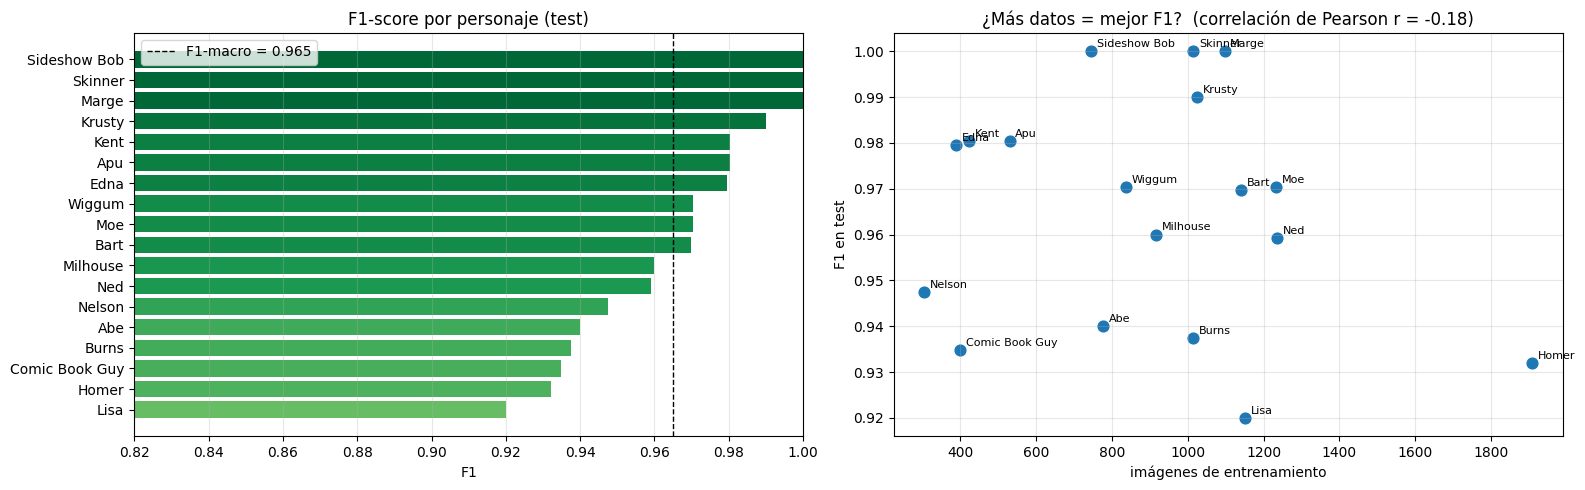

In [28]:
por_clase = reporte.iloc[:NUM_CLASSES].copy()
por_clase.index = [NOMBRE_CORTO[i] for i in range(NUM_CLASSES)]
por_clase["imágenes train"] = np.bincount(y_tr, minlength=NUM_CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
orden = por_clase.sort_values("f1-score")
axes[0].barh(orden.index, orden["f1-score"], color=plt.cm.RdYlGn((orden["f1-score"] - 0.6) / 0.4))
axes[0].axvline(METRICAS_TEST["f1_macro"], color="k", ls="--", lw=1, label=f"F1-macro = {METRICAS_TEST['f1_macro']:.3f}")
axes[0].set(xlim=(max(0, orden["f1-score"].min() - 0.1), 1.0), title="F1-score por personaje (test)", xlabel="F1")
axes[0].legend(); axes[0].grid(axis="x", alpha=0.3)
axes[1].scatter(por_clase["imágenes train"], por_clase["f1-score"], s=60)
for nombre, fila in por_clase.iterrows():
    axes[1].annotate(nombre, (fila["imágenes train"], fila["f1-score"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
corr = np.corrcoef(por_clase["imágenes train"], por_clase["f1-score"])[0, 1]
axes[1].set(xlabel="imágenes de entrenamiento", ylabel="F1 en test",
            title=f"¿Más datos = mejor F1?  (correlación de Pearson r = {corr:.2f})")
axes[1].grid(alpha=0.3)
plt.tight_layout()
guardar_figura("06_f1_por_personaje")
plt.show()

**Lectura:** la correlación entre la cantidad de imágenes de entrenamiento y el F1 es prácticamente nula (r = −0,18). Homer, la clase con más datos, está entre las peores, y Sideshow Bob, con menos de la mitad de imágenes, es perfecto. El rendimiento depende más de **qué tan distintivo es el personaje** (pelo, color, ropa) que de la cantidad de ejemplos. Esto es coherente con que los pesos de clase no mejoraran el modelo (E8).

#### 6.2 Matriz de confusión

El color representa la **proporción por fila** (*recall* de cada personaje) y el número, la cantidad de imágenes. La diagonal son los aciertos; las celdas fuera de la diagonal muestran **con quién se confunde cada personaje**.

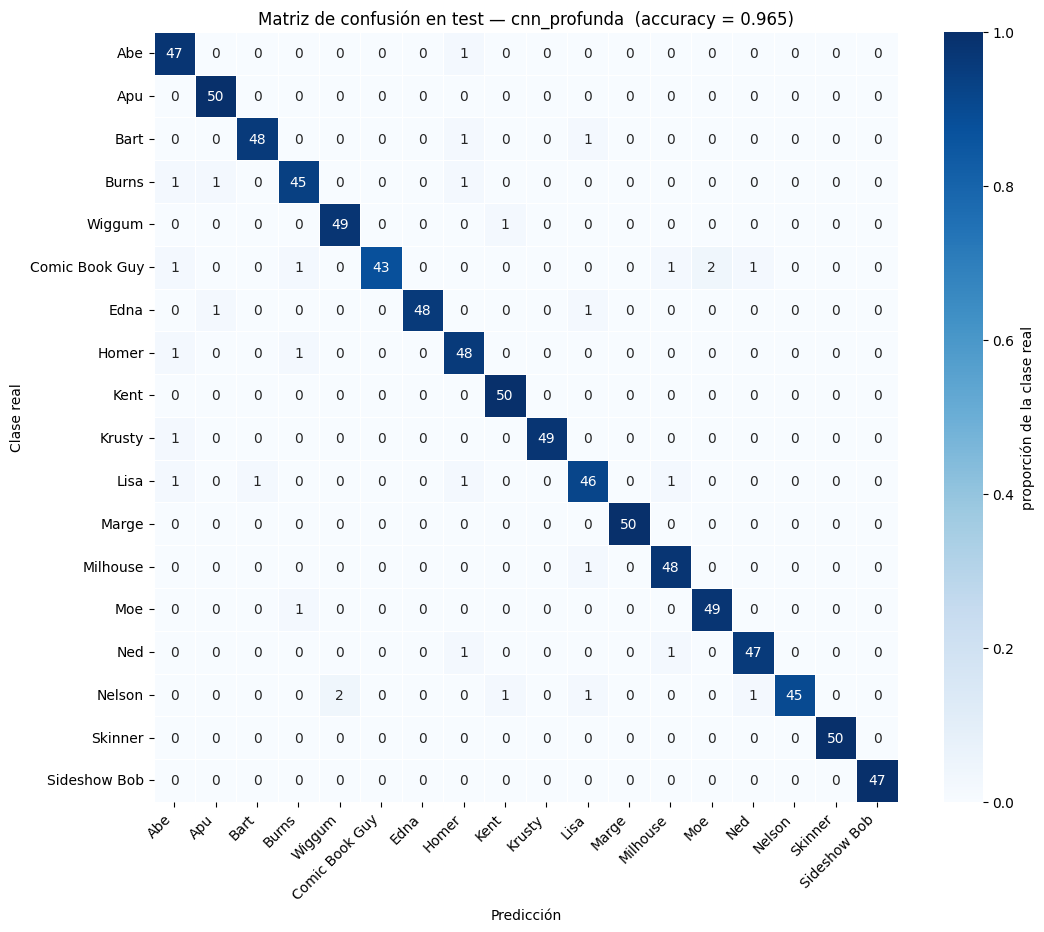

Total de errores: 31 de 890 imágenes


,clase real,predicha como,n.º de imágenes
0,Comic Book Guy,Moe,2
1,Nelson,Wiggum,2
2,Abe,Homer,1
3,Bart,Homer,1
4,Bart,Lisa,1
5,Burns,Abe,1
6,Burns,Apu,1
7,Burns,Homer,1
8,Wiggum,Kent,1
9,Comic Book Guy,Abe,1


In [29]:
cm = confusion_matrix(y_te, y_pred, labels=np.arange(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
etiquetas = [NOMBRE_CORTO[i] for i in range(NUM_CLASSES)]
plt.figure(figsize=(12, 10))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", xticklabels=etiquetas, yticklabels=etiquetas,
            cbar_kws={"label": "proporción de la clase real"}, linewidths=0.5, linecolor="white")
plt.xlabel("Predicción"); plt.ylabel("Clase real")
plt.title(f"Matriz de confusión en test — {NOMBRE_FINAL}  (accuracy = {METRICAS_TEST['accuracy']:.3f})")
plt.xticks(rotation=45, ha="right")
guardar_figura("06_matriz_confusion")
plt.show()

errores = [(NOMBRE_CORTO[i], NOMBRE_CORTO[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES)
           if i != j and cm[i, j] > 0]
top_confusiones = pd.DataFrame(sorted(errores, key=lambda e: -e[2])[:10], columns=["clase real", "predicha como", "n.º de imágenes"])
print(f"Total de errores: {int(cm.sum() - np.trace(cm))} de {cm.sum()} imágenes")
display(top_confusiones)

**Lectura de la matriz de confusión:** los 31 errores están **dispersos**; ningún par de personajes se confunde más de 2 veces, así que no hay una confusión sistemática grave. Los patrones más claros:
- **Comic Book Guy** (6 errores, *recall* 0,88) y **Nelson** (5 errores, *recall* 0,90) son los personajes con más fallos.
- Las columnas **Homer** y **Abe** reciben 5 falsos positivos cada una: ante una imagen dudosa de un personaje amarillo, calvo o canoso, el modelo tiende a responder "Homer" o "Abe".
- Confusiones entre personajes visualmente parecidos: Bart ↔ Lisa (familia, mismo tamaño y pelo en punta), Burns ↔ Abe ↔ Homer (adultos mayores calvos).

#### 6.3 Ejemplos de aciertos y errores, y confianza del modelo

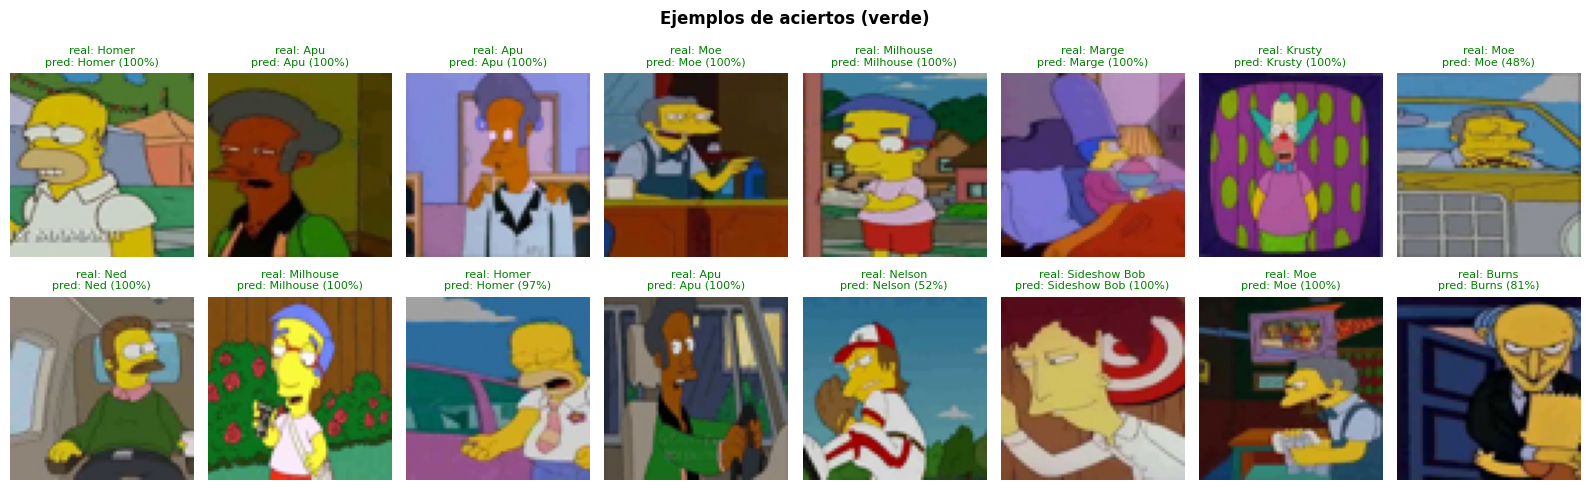

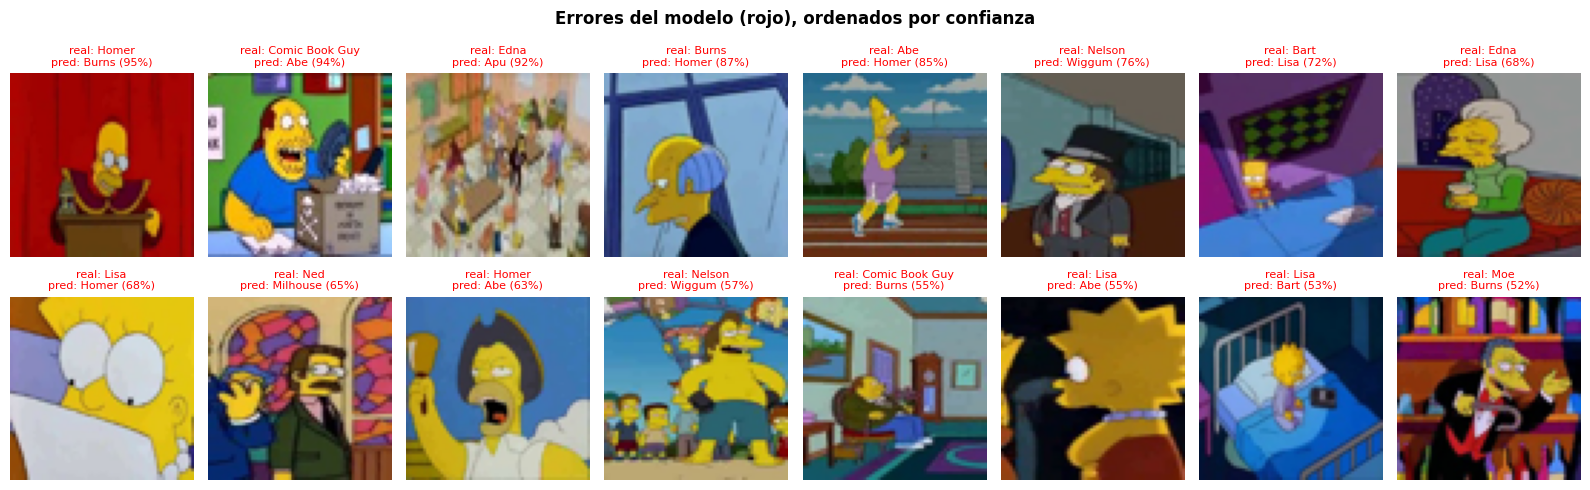

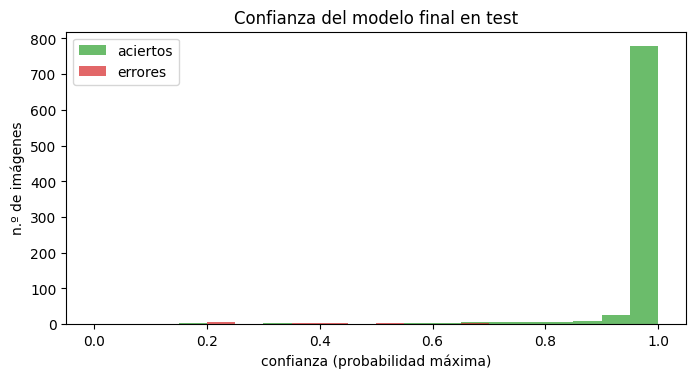

Si solo se aceptan predicciones con confianza >= 50%: se cubre el 97.2% de las imágenes con accuracy = 98.15%
Si solo se aceptan predicciones con confianza >= 70%: se cubre el 94.4% de las imágenes con accuracy = 99.17%
Si solo se aceptan predicciones con confianza >= 90%: se cubre el 91.0% de las imágenes con accuracy = 99.63%


In [30]:
def mostrar_ejemplos(indices, titulo, archivo):
    filas = int(np.ceil(len(indices) / 8))
    fig, axes = plt.subplots(filas, 8, figsize=(16, 2.6 * filas))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, i in zip(np.ravel(axes), indices):
        ax.imshow(X_te[i])
        ok = y_pred[i] == y_te[i]
        ax.set_title(f"real: {NOMBRE_CORTO[y_te[i]]}\npred: {NOMBRE_CORTO[y_pred[i]]} ({probs_test[i].max():.0%})",
                     fontsize=8, color="green" if ok else "red")
    plt.suptitle(titulo, fontweight="bold")
    plt.tight_layout()
    guardar_figura(archivo)
    plt.show()


rng = np.random.default_rng(SEED)
aciertos_idx = np.where(y_pred == y_te)[0]
errores_idx = np.where(y_pred != y_te)[0]
mostrar_ejemplos(rng.choice(aciertos_idx, min(16, len(aciertos_idx)), replace=False), "Ejemplos de aciertos (verde)", "06_ejemplos_aciertos")
if len(errores_idx):
    mostrar_ejemplos(errores_idx[np.argsort(-probs_test[errores_idx].max(1))][:16],
                     "Errores del modelo (rojo), ordenados por confianza", "06_ejemplos_errores")

# Distribución de la confianza (probabilidad máxima) en aciertos vs errores
conf = probs_test.max(axis=1)
plt.figure(figsize=(8, 3.8))
plt.hist(conf[y_pred == y_te], bins=20, range=(0, 1), alpha=0.7, label="aciertos", color="tab:green")
plt.hist(conf[y_pred != y_te], bins=20, range=(0, 1), alpha=0.7, label="errores", color="tab:red")
plt.xlabel("confianza (probabilidad máxima)"); plt.ylabel("n.º de imágenes"); plt.legend()
plt.title("Confianza del modelo final en test")
guardar_figura("06_confianza")
plt.show()
for umbral in (0.5, 0.7, 0.9):
    m = conf >= umbral
    if m.sum() == 0:
        continue
    print(f"Si solo se aceptan predicciones con confianza >= {umbral:.0%}: se cubre el {m.mean():.1%} de las imágenes "
          f"con accuracy = {(y_pred[m] == y_te[m]).mean():.2%}")

**Lectura:** los aciertos se concentran con confianza cercana a 100 %, mientras que los errores tienden a tener confianza menor. En la práctica, esto permite usar un **umbral de confianza**: con ≥ 70 % el modelo resuelve solo el 94,4 % de las imágenes con 99,2 % de acierto y deriva el 5,6 % dudoso a revisión humana. En los ejemplos de error se ven las causas: **disfraces o ropa atípica** (Homer con toga → Burns), **varios personajes en la escena** (Ned junto a Wiggum), **personaje lejano o parcial** y **escenas multitudinarias** (Edna → Apu).

#### 6.4 Uso del modelo: predicción de una imagen nueva

Función lista para usar en una aplicación: recibe la ruta de una imagen y devuelve los 3 personajes más probables.

In [31]:
def predecir_personaje(ruta_imagen, top=3):
    tam = final["img_size"]
    with Image.open(ruta_imagen) as img:
        x = np.asarray(img.convert("RGB").resize((tam, tam)), dtype=np.uint8)[None]
    p = final["predecir"](x)[0]
    return [(MAP_CHARACTERS[i], float(p[i])) for i in np.argsort(-p)[:top]]


ejemplos = sorted(glob.glob(os.path.join(DIR_TEST, "**", "*.jpg"), recursive=True))
for ruta in rng.choice(ejemplos, 4, replace=False):
    print(os.path.basename(ruta), "->", [(n, f"{p:.1%}") for n, p in predecir_personaje(ruta)])

nelson_muntz_7.jpg -> [('nelson_muntz', '16.7%'), ('principal_skinner', '12.6%'), ('homer_simpson', '11.9%')]


apu_nahasapeemapetilon_39.jpg -> [('apu_nahasapeemapetilon', '100.0%'), ('homer_simpson', '0.0%'), ('sideshow_bob', '0.0%')]


krusty_the_clown_8.jpg -> [('krusty_the_clown', '100.0%'), ('chief_wiggum', '0.0%'), ('apu_nahasapeemapetilon', '0.0%')]
chief_wiggum_13.jpg -> [('chief_wiggum', '91.1%'), ('milhouse_van_houten', '5.8%'), ('krusty_the_clown', '0.8%')]


#### 6.5 Confirmación: desempeño de **todos** los modelos en test

Esta tabla **no se usó para elegir el modelo** (la elección se hizo con validación); sirve para comprobar que el ranking obtenido en validación **se mantiene** con datos nunca vistos, es decir, que la selección no fue fruto del azar.

,framework,val F1 macro,test loss,test accuracy,test precision (macro),test recall (macro),test F1 macro,test F1 weighted
modelo,,,,,,,,
cnn_profunda,Keras,0.9426,0.1195,0.9652,0.9662,0.9652,0.9651,0.9651
mobilenetv2_finetuning,Keras,0.9176,0.1266,0.9640,0.9654,0.9642,0.9643,0.9641
E7_aumentacion,Keras,0.9042,0.1722,0.9528,0.9544,0.9530,0.9529,0.9528
E1_base,Keras,0.8669,0.1904,0.9472,0.9503,0.9471,0.9470,0.9470
pytorch_cnn_simple,PyTorch,0.8376,0.2584,0.9258,0.9323,0.9259,0.9266,0.9265
mobilenetv2_extraccion,Keras,0.6767,1.0088,0.7056,0.7342,0.7060,0.7067,0.7066


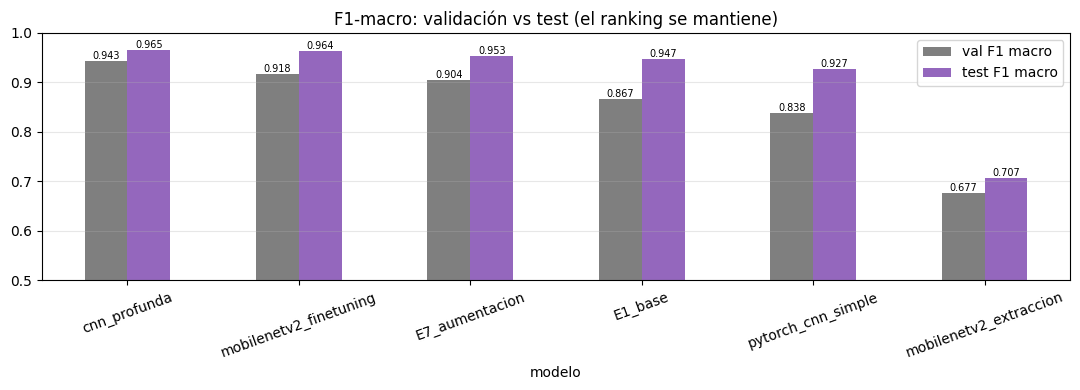

Modelo final guardado en resultados/modelo_final_simpsons.keras


In [32]:
filas = []
for n in COMPARADOS:
    r = RESULTADOS[n]
    Xt, yt = DATOS[r["img_size"]]["test"]
    m = metricas(yt, r["predecir"](Xt))
    filas.append({"modelo": n, "framework": r["framework"], "val F1 macro": r["val"]["f1_macro"],
                  "test loss": m["loss"], "test accuracy": m["accuracy"], "test precision (macro)": m["precision_macro"],
                  "test recall (macro)": m["recall_macro"], "test F1 macro": m["f1_macro"], "test F1 weighted": m["f1_weighted"]})
tabla_test = pd.DataFrame(filas).set_index("modelo").sort_values("test F1 macro", ascending=False)
display(tabla_test.style.format(precision=4, subset=tabla_test.columns[1:]).highlight_max(subset=["test accuracy", "test F1 macro"], color="#c6efce"))
tabla_test.to_csv(os.path.join(DIR_RESULTADOS, "tabla_test_todos.csv"))

ax = tabla_test[["val F1 macro", "test F1 macro"]].plot(kind="bar", figsize=(11, 4), rot=20, color=["tab:gray", "tab:purple"])
ax.set_ylim(0.5, 1); ax.grid(axis="y", alpha=0.3); ax.set_title("F1-macro: validación vs test (el ranking se mantiene)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7)
plt.tight_layout()
guardar_figura("06_validacion_vs_test")
plt.show()

# Se guarda el modelo final con un nombre explícito
if final["framework"] == "Keras":
    keras.models.load_model(os.path.join(DIR_RESULTADOS, f"{NOMBRE_FINAL}.keras")).save(os.path.join(DIR_RESULTADOS, "modelo_final_simpsons.keras"))
    print("Modelo final guardado en resultados/modelo_final_simpsons.keras")

**Lectura:** el orden de los modelos es **idéntico** en validación y en test, lo que confirma que la selección con validación fue robusta y no producto del azar. Todos los modelos rinden más en test (+2 a +9 pp) porque las imágenes de prueba son más "limpias" (personaje centrado y en primer plano). Por lo mismo, la cifra de validación es una estimación más conservadora para fotogramas reales. En test, la CNN profunda (0,965) y MobileNetV2 *fine-tuning* (0,964) quedan prácticamente empatadas (diferencia de 1 imagen); la elección se apoya en la ventaja de 2,5 pp en validación, un conjunto más grande y difícil.

### 7. Conclusiones

#### 7.1 Modelo elegido y desempeño final

Se eligió la **CNN profunda** (estilo VGG: 8 convoluciones 3×3 con *BatchNormalization*, *GlobalAveragePooling*, *Dropout* + L2, *data augmentation*, Adam con `ReduceLROnPlateau`), porque obtuvo el **mejor F1-macro en validación (0,943)** entre las 5 alternativas exploradas. En el conjunto de prueba (890 imágenes nunca vistas) logra:

| Métrica (test) | Valor |
|---|---|
| **Accuracy** | **96,5 %** (859 de 890 aciertos; 31 errores) |
| **F1-score macro** | **0,965** |
| Precision macro / Recall macro | 0,966 / 0,965 |
| F1 weighted | 0,965 |
| Loss (entropía cruzada) | 0,120 |

Como el test está balanceado, F1-macro y F1-weighted coinciden. Precision y recall también son casi iguales, así que el modelo **no tiene un sesgo sistemático** hacia ningún personaje: comete tantos falsos positivos como falsos negativos. **Todos los personajes superan F1 = 0,92**, y tres (Marge, Skinner y Sideshow Bob) se clasifican sin errores.

**Progresión del rendimiento** (F1-macro en validación), en la que cada decisión respaldada por evidencia sumó mejora:

`CNN base 0,867` → `+ data augmentation 0,904 (+3,7 pp)` → `+ arquitectura profunda con BN y GAP 0,943 (+3,8 pp)` = **+7,6 pp en total**, y la *loss* de validación bajó de 0,516 a 0,219 (−58 %).

#### 7.2 ¿Qué personajes confunde el modelo y por qué?

- Los errores se concentran en **Comic Book Guy** (*recall* 0,88: 2 veces confundido con Moe), **Nelson** (*recall* 0,90: 2 veces con el jefe Wiggum), **Lisa** (F1 0,92: confundida con Bart, Abe, Homer y Milhouse) y **Homer / Abe**, que son los destinos más frecuentes de los errores (5 falsos positivos cada uno, con *precision* ≈ 0,90).
- **Causas observadas en los ejemplos de error:**
  1. **Rasgos compartidos:** Bart y Lisa tienen la misma piel, tamaño y peinado en punta; Homer, Abe y Burns son hombres calvos o canosos de silueta parecida. A 64×64 píxeles los detalles que los distinguen (arrugas, nariz de Burns, barba de Homer) ocupan muy pocos píxeles.
  2. **Vestimenta atípica:** Homer con una toga roja fue clasificado como Burns, Abe con ropa deportiva como Homer y Nelson con sombrero de copa como Wiggum. El modelo aprendió (con razón) que **la ropa es un rasgo distintivo**, y falla cuando el personaje aparece disfrazado.
  3. **Varios personajes en el cuadro o personaje lejano/parcial:** en algunas imágenes aparecen dos personajes (p. ej. Ned junto a Wiggum) o el personaje ocupa una parte mínima de la escena. El problema se planteó con **una sola etiqueta por imagen**, por lo que estas escenas son ambiguas incluso para una persona.
- **La cantidad de datos no explica el desempeño** (correlación imágenes de entrenamiento vs F1: r = −0,18). Homer, con más imágenes (~1.900), tiene uno de los F1 más bajos (0,93) porque aparece en contextos muy variados y "atrae" las predicciones dudosas de personajes amarillos parecidos. Sideshow Bob, con menos de la mitad de imágenes, logra F1 = 1,0 gracias a su pelo rojo inconfundible. **Lo que manda es qué tan distintivos son los rasgos visuales**, lo que coincide con que los pesos de clase no ayudaran (E8).

#### 7.3 Impacto en la solución del caso

- Con 96,5 % de *accuracy* el modelo es útil para **etiquetar automáticamente fotogramas** (catalogar escenas, buscar apariciones de un personaje, generar metadatos).
- El análisis de confianza permite un **esquema semiautomático**: si solo se aceptan predicciones con probabilidad ≥ 70 %, el modelo clasifica automáticamente el **94,4 %** de las imágenes con **99,2 % de acierto**, y el 5,6 % restante se envía a revisión humana. Con umbral ≥ 90 % se cubre el 91 % con 99,6 % de acierto.
- Es liviano (1,25 M de parámetros, ~5 MB de pesos) y predice en ~2 ms por imagen en CPU, por lo que puede **desplegarse sin GPU**.

#### 7.4 Validación vs test: una observación importante

Todos los modelos obtienen en test entre 2 y 9 pp **más** que en validación, y **el ranking se mantiene idéntico** (gráfico de la sección 6.5), lo que confirma que la selección fue robusta. La diferencia se explica porque el conjunto de prueba entregado tiene imágenes **más "limpias"** (personaje centrado, en primer plano, una imagen por escena), mientras que la validación, extraída del conjunto de entrenamiento, incluye fotogramas más difíciles (personajes pequeños, varios personajes, escenas oscuras). Por eso **la cifra de validación (94,4 %) es una estimación más conservadora** del rendimiento con fotogramas reales sin curar. También hay que considerar el tamaño del test: con 890 imágenes, la *accuracy* de 96,5 % tiene un margen de ±1,2 pp (IC 95 %), así que en test la CNN profunda y MobileNetV2 *fine-tuning* (96,4 %) están **estadísticamente empatadas**. La elección se sostiene en la ventaja de 2,5 pp en validación (más imágenes y más difíciles), en su menor tamaño y en su mayor velocidad.

#### 7.5 Limitaciones

- **Cómputo:** todo se entrenó en **CPU** (≈ 134 min el cuaderno completo). Esto obligó a usar 64×64 píxeles para los modelos propios y a limitar las épocas. La CNN profunda **seguía mejorando** en su última época.
- **Una corrida por configuración:** no se repitieron los experimentos con varias semillas ni se usó validación cruzada, así que diferencias menores a ~1 pp (p. ej. E7 vs E8) deben interpretarse con cautela.
- **Una etiqueta por imagen:** el planteamiento no contempla escenas con varios personajes ni personajes fuera de los 18 (el modelo siempre elige uno de los 18).
- **Comparación con resoluciones distintas:** MobileNetV2 usó 96 px y las CNN propias 64 px, por requisito de los pesos pre-entrenados.

#### 7.6 Mejoras con más tiempo o recursos

1. **Entrenar la CNN profunda más épocas** (30–50) en GPU y con mayor resolución (96–128 px) para recuperar detalles finos (arrugas, ojos, accesorios).
2. ***Fine-tuning* más profundo** de MobileNetV2 o probar **EfficientNet / ResNet50** en GPU, descongelando más capas.
3. **Ensamble** de la CNN profunda y MobileNetV2 (promediar probabilidades): cometen errores distintos y su combinación suele superar a cada uno.
4. **Aumentación más fuerte** (*mixup*, *cutout*/*random erasing*) y *label smoothing* para mejorar la robustez ante disfraces y oclusiones.
5. **Varias semillas o validación cruzada estratificada** para comparar configuraciones con intervalos de confianza.
6. **Clase "desconocido"** mediante umbral de confianza y **Grad-CAM** para visualizar en qué zonas de la imagen se fija la red y explicar sus errores.

#### 7.7 Aprendizajes sobre las herramientas

- **TensorFlow/Keras** fue la herramienta más productiva: la aumentación dentro del modelo, los *callbacks* (`EarlyStopping`, `ModelCheckpoint`, `ReduceLROnPlateau`) y `keras.applications` permitieron probar 11 configuraciones con poco código. Como **debilidad**, no tiene soporte GPU nativo en Windows y algunos errores en modo grafo son poco claros.
- **PyTorch** produjo un modelo equivalente, pero exigió programar a mano el ciclo de entrenamiento, el *early stopping* y el guardado, y en CPU fue ~2× más lento por época. Su fortaleza es el control total, valioso para investigación.
- El **ajuste de hiperparámetros fue tan importante como la arquitectura**: la misma red pasó de 1 % a 87 % de F1 solo cambiando la tasa de aprendizaje, y la aumentación de datos aportó más que cualquier otro ajuste sobre la CNN simple.

#### Referencias

- Simonyan, K., & Zisserman, A. (2015). *Very Deep Convolutional Networks for Large-Scale Image Recognition*. ICLR.
- Ioffe, S., & Szegedy, C. (2015). *Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift*. ICML.
- Srivastava, N., et al. (2014). *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*. JMLR, 15.
- Lin, M., Chen, Q., & Yan, S. (2014). *Network In Network*. ICLR (*Global Average Pooling*).
- Kingma, D. P., & Ba, J. (2015). *Adam: A Method for Stochastic Optimization*. ICLR.
- Sandler, M., et al. (2018). *MobileNetV2: Inverted Residuals and Linear Bottlenecks*. CVPR.
- Goyal, P., et al. (2017). *Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour*. arXiv:1706.02677.
- Chollet, F. (2021). *Deep Learning with Python* (2.ª ed.). Manning. Documentación de Keras: *Transfer learning & fine-tuning* (keras.io).
- Attia, A. *The Simpsons Characters Data*. Kaggle.